<a href="https://colab.research.google.com/github/abdalrahmantawfiqsultan/Duhkan_quraan/blob/main/whisper_dukhan2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fine-Tuning Whisper on Quranic Recitations of سورة الدخان (Quran-MD)
## 80% / 10% / 10% Reciter Split + Comprehensive Audio/Text Preprocessing + Multi-Stage Augmentation + Rich Visualizations
This script is structured into sequential cells (`# %%`) ready to run in **Google Colab**.
Before starting, enable the GPU accelerator from the menu:
`Runtime` -> `Change runtime type` -> `T4 GPU`

## Step 2 — Install Required Libraries

In [4]:
get_ipython().system(
    'pip -q install '
    '"transformers==4.46.3" '
    '"datasets==3.3.2" '
    '"accelerate>=1.1,<2" '
    '"evaluate==0.4.3" '
    '"jiwer==3.0.5" '
    '"librosa>=0.10" '
    '"scipy>=1.10" '
    '"arabic-reshaper>=3.0.0" '
    '"python-bidi>=0.4.2" '
    'soundfile jiwer'
)

## Step 3 — Verify GPU Availability, Configure Global Warning Filters & Font Settings

In [5]:
import os
import shutil
import warnings
import logging
import torch
import matplotlib
import matplotlib.pyplot as plt
from transformers.utils import logging as hf_logging

# Globally silence Hugging Face "Trainer.tokenizer is now deprecated" and Matplotlib missing glyph warnings
warnings.filterwarnings("ignore", message=".*Trainer.tokenizer is now deprecated.*")
warnings.filterwarnings("ignore", message=".*Glyph .* missing from font.*")
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="matplotlib")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
hf_logging.set_verbosity_error()

def configure_matplotlib_arabic():
    """
    Configures Matplotlib to use DejaVu Sans after applying any plot style.
    Passing `rc={"font.sans-serif": ["DejaVu Sans"]}` directly inside `plt.style.use`
    prevents seaborn styles from overriding the font back to Liberation Sans.
    """
    style_name = "seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default"
    plt.style.use(style_name)
    matplotlib.rcParams["font.family"] = "sans-serif"
    matplotlib.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "Tahoma"]
    matplotlib.rcParams["axes.unicode_minus"] = False

configure_matplotlib_arabic()

assert torch.cuda.is_available(), (
    "No GPU detected! Please open Runtime -> Change runtime type and select T4 GPU."
)

print("GPU Device:", torch.cuda.get_device_name(0))
print(
    "Free local disk space:",
    round(shutil.disk_usage("/content").free / 1024**3, 2),
    "GB",
)
print("PyTorch version:", torch.__version__)

GPU Device: Tesla T4
Free local disk space: 193.01 GB
PyTorch version: 2.11.0+cu130


## Step 4 — Mount Google Drive and Configure Project Directories

In [6]:
import glob
from datetime import datetime
from google.colab import drive

drive.mount("/content/drive")

SURAH_ID = 44
SURAH_NAME_AR = "سورة الدخان"

PROJECT_DIR = "/content/drive/MyDrive/quran-whisper-dukhan"
RAW_DIR = os.path.join(PROJECT_DIR, "raw_dataset")
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints_reciter_split")
FINAL_DIR = os.path.join(PROJECT_DIR, "final_model_reciter_split")
PLOTS_DIR = os.path.join(PROJECT_DIR, "visualizations")

os.makedirs(PROJECT_DIR, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Target Surah:", SURAH_NAME_AR, f"(ID: {SURAH_ID})")

Mounted at /content/drive
Project directory: /content/drive/MyDrive/quran-whisper-dukhan
Target Surah: سورة الدخان (ID: 44)


## Step 4.2 — Clean Up Old Training Folders in Google Drive to Start Fresh
This cell scans your project directory in Google Drive, finds older training folders (`checkpoints*`, `final_model*`, and old visualization folders), sorts them from oldest to newest, and deletes them so you can start a fresh training run without wasting Google Drive storage.
Note: `raw_dataset` is preserved so you do not need to re-download the dataset from Hugging Face.

In [7]:
CLEANUP_OLD_TRAINING_RUNS = True
DELETE_ALL_TRAINING_ARTIFACTS = True  # Set to True to wipe all previous checkpoints/models and start from scratch
KEEP_NEWEST_N_FOLDERS = 0             # Only used if DELETE_ALL_TRAINING_ARTIFACTS is False

if CLEANUP_OLD_TRAINING_RUNS and os.path.isdir(PROJECT_DIR):
    candidate_prefixes = ("checkpoints", "final_model", "visualizations", "logs", "runs")
    training_folders = []

    for entry in os.scandir(PROJECT_DIR):
        if entry.is_dir() and entry.name != "raw_dataset":
            if entry.name.startswith(candidate_prefixes):
                mtime = entry.stat().st_mtime
                training_folders.append((mtime, entry.path, entry.name))

    # Sort folders from oldest to newest by modification timestamp
    training_folders.sort(key=lambda x: x[0])

    if not training_folders:
        print("No old training folders found in Google Drive. Ready for a clean start!")
    else:
        print(f"Found {len(training_folders)} existing training folder(s) in Google Drive:")
        for mtime, path, name in training_folders:
            timestamp_str = datetime.fromtimestamp(mtime).strftime("%Y-%m-%d %H:%M:%S")
            print(f"  - {name} (Last modified: {timestamp_str})")

        if DELETE_ALL_TRAINING_ARTIFACTS:
            folders_to_delete = training_folders
        else:
            cutoff = max(0, len(training_folders) - KEEP_NEWEST_N_FOLDERS)
            folders_to_delete = training_folders[:cutoff]

        for mtime, path, name in folders_to_delete:
            print(f"Deleting old folder: {path} ...")
            shutil.rmtree(path, ignore_errors=True)

        # Also clean up old standalone PNG plot files in the root project folder
        old_pngs = glob.glob(os.path.join(PROJECT_DIR, "*.png"))
        for png_path in old_pngs:
            try:
                os.remove(png_path)
                print(f"Removed old plot file: {os.path.basename(png_path)}")
            except OSError:
                pass

        print("Google Drive cleanup complete! Starting fresh.")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)
print("Active Checkpoints directory:", CHECKPOINT_DIR)
print("Active Visualizations directory:", PLOTS_DIR)

Found 3 existing training folder(s) in Google Drive:
  - checkpoints_reciter_split (Last modified: 2026-10-25 09:29:08)
  - visualizations (Last modified: 2026-10-25 09:29:08)
  - final_model_reciter_split (Last modified: 2026-10-25 10:46:44)
Deleting old folder: /content/drive/MyDrive/quran-whisper-dukhan/checkpoints_reciter_split ...
Deleting old folder: /content/drive/MyDrive/quran-whisper-dukhan/visualizations ...
Deleting old folder: /content/drive/MyDrive/quran-whisper-dukhan/final_model_reciter_split ...
Google Drive cleanup complete! Starting fresh.
Active Checkpoints directory: /content/drive/MyDrive/quran-whisper-dukhan/checkpoints_reciter_split
Active Visualizations directory: /content/drive/MyDrive/quran-whisper-dukhan/visualizations


## Step 4.5 — Configure Hugging Face API Token (`HF_TOKEN`)

In [8]:
from getpass import getpass
from google.colab import userdata
from huggingface_hub import login

hf_token = None

try:
    hf_token = userdata.get("HF_TOKEN")
    print("Successfully retrieved HF_TOKEN from Colab Secrets.")
except Exception:
    print("HF_TOKEN not found in Colab Secrets.")

if not hf_token:
    hf_token = getpass("Enter your Hugging Face API token (or press Enter to skip): ").strip()

if hf_token:
    os.environ["HF_TOKEN"] = hf_token
    login(token=hf_token, add_to_git_credential=False)
    print("Logged in to Hugging Face Hub successfully!")
else:
    print("Proceeding without an API token (public access mode).")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Successfully retrieved HF_TOKEN from Colab Secrets.
Logged in to Hugging Face Hub successfully!


## Step 5 — Filter and Download Records for سورة الدخان (Surah 44) Only

In [9]:
from huggingface_hub import HfApi
from datasets import (
    load_dataset,
    Dataset,
    Audio,
    load_from_disk,
    concatenate_datasets,
)

DATASET_ID = "Buraaq/quran-md-ayahs"
LOCAL_RAW_DIR = "/content/dukhan_raw_dataset"

# Dictionary mapping standard reciter IDs to Arabic Reciter Names
RECITER_ARABIC_MAP = {
    "abdul_basit_murattal": "عبد الباسط عبد الصمد - مرتل",
    "abdul_basit_mujawwad": "عبد الباسط عبد الصمد - مجود",
    "abdullah_basfar": "عبد الله بصفر",
    "abdurrahmaan_as_sudais": "عبد الرحمن السديس",
    "abu_bakr_ash_shaatree": "أبو بكر الشاطري",
    "ahmed_ibn_ali_al_ajamy": "أحمد بن علي العجمي",
    "alafasy": "مشاري راشد العفاسي",
    "ali_jaber": "علي جابر",
    "ayman_suowaid": "أيمن سويد",
    "banna": "محمود علي البنا",
    "fares_abbad": "فارس عباد",
    "ghamadi": "سعد الغامدي",
    "hani_ar_rifai": "هاني الرفاعي",
    "hudhaify": "علي بن عبد الرحمن الحذيفي",
    "husary": "محمود خليل الحصري",
    "husary_muallim": "محمود خليل الحصري - معلم",
    "husary_mujawwad": "محمود خليل الحصري - مجود",
    "ibrahim_akhdar": "إبراهيم الأخضر",
    "khalefa_al_tunaiji": "خليفة الطنيجي",
    "maher_al_muaiqly": "ماهر المعيقلي",
    "minshawy_mujawwad": "محمد صديق المنشاوي - مجود",
    "minshawy_murattal": "محمد صديق المنشاوي - مرتل",
    "mohammad_al_tablaway": "محمد محمود الطبلاوي",
    "muhammad_ayyoub": "محمد أيوب",
    "muhammad_jibreel": "محمد جبريل",
    "muhsin_al_qasim": "عبد المحسن القاسم",
    "nasser_al_qatami": "ناصر القطامي",
    "salah_al_budair": "صلاح البدير",
    "salah_bukhatir": "صلاح بو خاطر",
    "saood_ash_shuraym": "سعود الشريم",
    "yasser_ad_dussary": "ياسر الدوسري",
}

def get_arabic_reciter_name(example_or_id):
    """Returns the Arabic name of the reciter from dataset metadata or mapping dictionary."""
    if isinstance(example_or_id, dict):
        if "reciter_ar" in example_or_id and example_or_id["reciter_ar"]:
            return str(example_or_id["reciter_ar"])
        rec_id = str(example_or_id.get("reciter_id", example_or_id.get("reciter_name", "")))
    else:
        rec_id = str(example_or_id)
    key = rec_id.strip().lower()
    if key in RECITER_ARABIC_MAP:
        return RECITER_ARABIC_MAP[key]
    for map_key, ar_name in RECITER_ARABIC_MAP.items():
        if map_key in key or key in map_key:
            return ar_name
    return rec_id

metadata_file = os.path.join(RAW_DIR, "dataset_info.json")

if os.path.isfile(metadata_file):
    print(f"Found cached dataset for {SURAH_NAME_AR} in Google Drive (skipping download).")
else:
    print(f"Searching Parquet files and filtering {SURAH_NAME_AR} (Surah ID: {SURAH_ID})...")
    api = HfApi()
    repo_files = api.list_repo_files(
        repo_id=DATASET_ID,
        repo_type="dataset",
    )
    parquet_files = [
        f"hf://datasets/{DATASET_ID}/{path}"
        for path in repo_files
        if path.startswith("data/") and path.endswith(".parquet")
    ]
    print("Parquet files found:", len(parquet_files))

    filtered_ds = load_dataset(
        "parquet",
        data_files=parquet_files,
        split="train",
        filters=[("surah_id", "==", SURAH_ID)],
    )

    print("Total records downloaded:", len(filtered_ds))
    print("Unique verses:", len(set(filtered_ds["ayah_id"])))
    if "reciter_id" in filtered_ds.column_names:
        print("Unique reciters:", len(set(filtered_ds["reciter_id"])))

    os.makedirs(RAW_DIR, exist_ok=True)
    filtered_ds.save_to_disk(RAW_DIR)
    print("Saved filtered dataset to Google Drive:", RAW_DIR)

Found cached dataset for سورة الدخان in Google Drive (skipping download).


## Step 6 — Copy Dataset to Local Colab Disk for Fast I/O

In [10]:
if not os.path.isfile(os.path.join(LOCAL_RAW_DIR, "dataset_info.json")):
    if os.path.exists(LOCAL_RAW_DIR):
        shutil.rmtree(LOCAL_RAW_DIR)
    shutil.copytree(RAW_DIR, LOCAL_RAW_DIR)

raw_dataset = load_from_disk(LOCAL_RAW_DIR)
print("Local dataset ready:", len(raw_dataset), "records")
print("Dataset columns:", raw_dataset.column_names)

# Build a lookup table from reciter_id to Arabic reciter name using dataset columns if available
reciter_col = "reciter_id" if "reciter_id" in raw_dataset.column_names else "reciter_name"
if "reciter_ar" in raw_dataset.column_names:
    for r_id, r_ar in zip(raw_dataset[reciter_col], raw_dataset["reciter_ar"]):
        if r_id and r_ar:
            RECITER_ARABIC_MAP[str(r_id).strip().lower()] = str(r_ar)

Local dataset ready: 1770 records
Dataset columns: ['surah_id', 'ayah_id', 'surah_name_ar', 'surah_name_en', 'surah_name_tr', 'ayah_count', 'ayah_ar', 'ayah_en', 'ayah_tr', 'reciter_id', 'reciter_name', 'audio']


## Step 7 — Split Dataset by Reciters (80% Training / 10% Evaluation / 10% Testing)
Out of the 30 reciters in سورة الدخان:
- **80% (24 reciters)** are allocated for **Training** ($\approx 1,416$ recordings across all 59 verses).
- **10% (3 reciters)** are allocated for **Evaluation / Validation** during training ($\approx 177$ recordings across all 59 verses).
- **10% (3 reciters)** are completely held out for **Final Testing** ($\approx 177$ recordings across all 59 verses).

In [11]:
import random

all_reciters = sorted(set(raw_dataset[reciter_col]))

rng = random.Random(42)
rng.shuffle(all_reciters)

# 10% for Evaluation (3 reciters), 10% for Testing (3 reciters), and 80% for Training (24 reciters)
n_eval_reciters = max(1, round(len(all_reciters) * 0.10))
n_test_reciters = max(1, round(len(all_reciters) * 0.10))

eval_reciters = set(all_reciters[:n_eval_reciters])
test_reciters = set(all_reciters[n_eval_reciters : n_eval_reciters + n_test_reciters])
train_reciters = set(all_reciters[n_eval_reciters + n_test_reciters :])

reciter_column = raw_dataset[reciter_col]

train_indices = [
    i for i, rec in enumerate(reciter_column)
    if rec in train_reciters
]
eval_indices = [
    i for i, rec in enumerate(reciter_column)
    if rec in eval_reciters
]
test_indices = [
    i for i, rec in enumerate(reciter_column)
    if rec in test_reciters
]

train_raw = raw_dataset.select(train_indices)
eval_raw = raw_dataset.select(eval_indices)
test_raw = raw_dataset.select(test_indices)

print(f"Surah: {SURAH_NAME_AR}")
print(f"Total Reciters: {len(all_reciters)}")
print(f"Training Reciters (80%):   {len(train_reciters)} reciters -> {len(train_raw)} audio records")
print(f"Evaluation Reciters (10%): {len(eval_reciters)} reciters  -> {len(eval_raw)} audio records")
print(f"Testing Reciters (10%):    {len(test_reciters)} reciters  -> {len(test_raw)} audio records")

print("\nHeld-out Evaluation Reciters (10% - Arabic):")
for r_id in sorted(eval_reciters):
    print(f"  - {get_arabic_reciter_name(r_id)} ({r_id})")

print("\nHeld-out Testing Reciters (10% - Arabic):")
for r_id in sorted(test_reciters):
    print(f"  - {get_arabic_reciter_name(r_id)} ({r_id})")

print("\nTraining Reciters (80% - Arabic):")
for r_id in sorted(train_reciters):
    print(f"  - {get_arabic_reciter_name(r_id)}")

print("\nVerses covered in Training:", len(set(train_raw["ayah_id"])), "/ 59")
print("Verses covered in Evaluation:", len(set(eval_raw["ayah_id"])), "/ 59")
print("Verses covered in Testing:", len(set(test_raw["ayah_id"])), "/ 59")

Surah: سورة الدخان
Total Reciters: 30
Training Reciters (80%):   24 reciters -> 1416 audio records
Evaluation Reciters (10%): 3 reciters  -> 177 audio records
Testing Reciters (10%):    3 reciters  -> 177 audio records

Held-out Evaluation Reciters (10% - Arabic):
  - فارس عباد (fares_abbad)
  - محمود خليل الحصري (husary)
  - محمد صديق المنشاوي - مرتل (minshawy_murattal)

Held-out Testing Reciters (10% - Arabic):
  - مشاري راشد العفاسي (alafasy)
  - محمد جبريل (muhammad_jibreel)
  - خليفة الطنيجي (tunaiji)

Training Reciters (80% - Arabic):
  - عبد الباسط عبد الصمد - مرتل
  - abdullaah_3awwaad_al_juhaynee
  - عبد الله بصفر
  - abdulsamad
  - عبد الرحمن السديس
  - أبو بكر الشاطري
  - علي جابر
  - ayman_sowaid
  - محمود علي البنا
  - سعد الغامدي
  - hani_rifai
  - علي بن عبد الرحمن الحذيفي
  - محمود خليل الحصري - مجود
  - hussary.teacher
  - إبراهيم الأخضر
  - محمد صديق المنشاوي - مجود
  - minshawy_teacher
  - mostafa_ismail
  - عبد المحسن القاسم
  - nasser_alqatami
  - سعود الشريم
  - م

## Step 8 — Load Whisper-Small and Enable Spectral Augmentation (SpecAugment)

In [12]:
import numpy as np
from transformers import (
    WhisperProcessor,
    WhisperForConditionalGeneration,
)

MODEL_NAME = "openai/whisper-small"

processor = WhisperProcessor.from_pretrained(
    MODEL_NAME,
    language="arabic",
    task="transcribe",
)

model = WhisperForConditionalGeneration.from_pretrained(MODEL_NAME)

model.generation_config.language = "arabic"
model.generation_config.task = "transcribe"
model.generation_config.forced_decoder_ids = None

# Enable SpecAugment for automatic spectral masking (Time & Feature Masking) during training
model.config.apply_spec_augment = True
model.config.mask_time_prob = 0.05
model.config.mask_time_length = 10
model.config.mask_feature_prob = 0.05
model.config.mask_feature_length = 10

# Disable KV cache during training to support gradient checkpointing
model.config.use_cache = False

print("Whisper model and processor loaded successfully (with SpecAugment enabled).")

preprocessor_config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

...

special_tokens_map.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/967M [00:00<?, ?B/s]

generation_config.json: 0.00B [00:00, ?B/s]

Whisper model and processor loaded successfully (with SpecAugment enabled).


## Step 9 — Resample Audio to 16 kHz and Filter Out Corrupted or >30s Clips Across All 3 Splits

In [13]:
import io
import soundfile as sf
import librosa
from datasets import Audio

MIN_AUDIO_SECONDS = 0.4
MAX_AUDIO_SECONDS = 30.0

# Cast with decode=False so Hugging Face doesn't automatically crash on corrupt formats
train_audio = train_raw.cast_column("audio", Audio(sampling_rate=16000, decode=False))
eval_audio = eval_raw.cast_column("audio", Audio(sampling_rate=16000, decode=False))
test_audio = test_raw.cast_column("audio", Audio(sampling_rate=16000, decode=False))

def is_valid_audio(example):
    try:
        audio_dict = example["audio"]
        if audio_dict is None or "bytes" not in audio_dict or audio_dict["bytes"] is None:
            return False

        audio_bytes = audio_dict["bytes"]
        with io.BytesIO(audio_bytes) as f:
            array, sample_rate = sf.read(f)

        if array.ndim > 1:
            array = array.mean(axis=-1)

    except Exception:
        return False

    if array is None or sample_rate is None or len(array) == 0:
        return False
    if not np.isfinite(array).all():
        return False

    duration = len(array) / sample_rate
    if duration < MIN_AUDIO_SECONDS or duration > MAX_AUDIO_SECONDS:
        return False
    if np.max(np.abs(array)) < 1e-4:
        return False
    return True

train_before = len(train_audio)
eval_before = len(eval_audio)
test_before = len(test_audio)

print("Filtering training, evaluation, and testing audio...")
train_audio = train_audio.filter(is_valid_audio, desc="Filtering training audio")
eval_audio = eval_audio.filter(is_valid_audio, desc="Filtering evaluation audio")
test_audio = test_audio.filter(is_valid_audio, desc="Filtering testing audio")

# Re-enable automatic decoding on the validated splits
train_audio = train_audio.cast_column("audio", Audio(sampling_rate=16000, decode=True))
eval_audio = eval_audio.cast_column("audio", Audio(sampling_rate=16000, decode=True))
test_audio = test_audio.cast_column("audio", Audio(sampling_rate=16000, decode=True))

print(
    f"Training audio (80%):   kept {len(train_audio)} / {train_before} "
    f"(removed {train_before - len(train_audio)} invalid or >30s records)"
)
print(
    f"Evaluation audio (10%): kept {len(eval_audio)} / {eval_before} "
    f"(removed {eval_before - len(eval_audio)} invalid or >30s records)"
)
print(
    f"Testing audio (10%):    kept {len(test_audio)} / {test_before} "
    f"(removed {test_before - len(test_audio)} invalid or >30s records)"
)

Filtering training, evaluation, and testing audio...


Filtering training audio:   0%|          | 0/1416 [00:00<?, ? examples/s]

Filtering evaluation audio:   0%|          | 0/177 [00:00<?, ? examples/s]

Filtering testing audio:   0%|          | 0/177 [00:00<?, ? examples/s]

Training audio (80%):   kept 1263 / 1416 (removed 153 invalid or >30s records)
Evaluation audio (10%): kept 177 / 177 (removed 0 invalid or >30s records)
Testing audio (10%):    kept 177 / 177 (removed 0 invalid or >30s records)


## Step 10 — Comprehensive Audio/Text Preprocessing & Multi-Stage Data Augmentation

### Part A: Deterministic Preprocessing Pipeline (Applied to Training, Evaluation & Testing):
1. **Mono Conversion & NaN/Inf Sanitization.**
2. **DC Offset Removal & Transient Click De-Spiking (`despike_transients`):** Suppresses sudden non-speech microphone pops.
3. **6th-Order Butterworth Band-Pass Filter ($65\text{ Hz} - 7600\text{ Hz}$):** Removes low-frequency hum ($<65\text{ Hz}$) and high-frequency aliasing noise ($>7600\text{ Hz}$).
4. **Stationary Spectral Noise Gate (`spectral_noise_gate`):** Estimates stationary background floor and gently attenuates low-energy noise bins in the STFT domain.
5. **Subtle Pre-Emphasis / High-Frequency Clarity Boost:** Enhances Arabic consonant articulation (pharyngeal, emphatic, and sibilant letters).
6. **Boundary Silence Trimming (`top_db=35`) with $120\text{ ms}$ Breath Margin:** Preserves final *Qalqalah*, *Hams*, and *Madd* releases.
7. **Internal Long-Pause Compression:** Compresses long internal pauses ($>0.32\text{ s}$) so Whisper's cross-attention stays aligned.
8. **Cosine Fade-In / Fade-Out Window ($15\text{ ms}$):** Eliminates boundary clicks.
9. **Target RMS Energy Normalization ($-20\text{ dBFS}$) + Soft-Knee Tanh Limiter (`0.95` ceiling).**
10. **Quranic Text Canonicalization (`preprocess_quran_text`):** Normalizes Unicode (`NFC`), strips zero-width characters, canonicalizes consecutive *Shaddah* + vowel ordering, and keeps all Quranic diacritics intact.

### Part B: Multi-Stage Waveform Augmentation (Applied to a 2nd copy of Training Data for 2x Dataset Size):
1. **Time Stretching (`librosa.effects.time_stretch`):** $0.90\times - 1.12\times$ rate perturbation.
2. **Pitch Shifting (`librosa.effects.pitch_shift`):** $\pm 1.2$ semitones.
3. **Vocal Tract Length / Formant Perturbation (`perturb_formants`):** Simulates different vocal tract resonances across unseen reciters.
4. **Simulated Mosque/Room Reverb:** Impulse response convolution with exponential decay.
5. **Random Parametric Band-Pass / Microphone EQ Filter.**
6. **Random Temporal Shift & Silence Padding.**
7. **Combined White & Pink ($1/f$) Ambient Noise Injection ($20\text{ dB} - 35\text{ dB}$ SNR).**

In [14]:
import re
import unicodedata
from scipy.signal import butter, sosfilt

SR = 16000
BANDPASS_SOS = butter(6, [65.0, 7600.0], btype="bandpass", fs=SR, output="sos")
aug_rng = np.random.default_rng(42)

def preprocess_quran_text(text):
    """Canonicalizes Quranic text while preserving all phonetic diacritics (Tashkeel)."""
    if not text:
        return ""
    text = unicodedata.normalize("NFC", str(text))
    # Remove invisible zero-width and directional formatting characters
    text = re.sub(r"[\u200B-\u200F\u202A-\u202E\uFEFF]", "", text)
    # Remove non-phonetic ornamental symbols (e.g., Rub El Hizb ۞ or Sajdah ۩) if present
    text = re.sub(r"[\u06DE\u06E9]", "", text)
    # Canonicalize Shaddah (\u0651) + Harakah ordering so Shaddah always precedes the vowel
    text = re.sub(r"([\u064B-\u0650\u0652\u0670])\u0651", "\u0651\\1", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def despike_transients(y, sigma_thresh=6.5):
    """Suppresses isolated single-sample digital clicks/pops without altering speech peaks."""
    diff = np.diff(y, prepend=y[0])
    std_diff = np.std(diff) + 1e-8
    spikes = np.abs(diff) > (sigma_thresh * std_diff)
    if np.any(spikes):
        y = y.copy()
        spike_indices = np.where(spikes)[0]
        for idx in spike_indices:
            if 0 < idx < len(y) - 1:
                y[idx] = 0.5 * (y[idx - 1] + y[idx + 1])
    return y

def spectral_noise_gate(y, sample_rate=SR, prop_decrease=0.65):
    """
    Gentle stationary spectral noise gating in the STFT domain.
    Estimates the noise floor from the quietest 10% frames and attenuates background hiss.
    """
    if len(y) < 1024:
        return y
    stft = librosa.stft(y, n_fft=512, hop_length=160, win_length=400)
    mag = np.abs(stft)
    frame_energy = np.mean(mag, axis=0)
    quiet_thresh = np.percentile(frame_energy, 10)
    quiet_frames = mag[:, frame_energy <= quiet_thresh]
    if quiet_frames.shape[1] == 0:
        return y
    noise_profile = np.mean(quiet_frames, axis=1, keepdims=True)
    mask = np.clip((mag - noise_profile) / (mag + 1e-8), 1.0 - prop_decrease, 1.0)
    stft_denoised = stft * mask
    y_denoised = librosa.istft(stft_denoised, hop_length=160, win_length=400, length=len(y))
    return y_denoised.astype(np.float32)

def compress_internal_pauses(y, sample_rate=SR, top_db=34, max_pause_sec=0.32):
    """
    Detects non-silent speech intervals and compresses overly long internal breathing pauses
    (common in Mujawwad recitations) down to `max_pause_sec` with smooth cross-fades.
    """
    if len(y) < int(0.8 * sample_rate):
        return y

    intervals = librosa.effects.split(y, top_db=top_db, frame_length=1024, hop_length=256)
    if len(intervals) <= 1:
        return y

    max_pause_samples = int(max_pause_sec * sample_rate)
    margin = int(0.06 * sample_rate)
    segments = []

    for idx, (start, end) in enumerate(intervals):
        s = max(0, start - margin) if idx == 0 else start
        e = min(len(y), end + margin) if idx == len(intervals) - 1 else end
        segments.append(y[s:e])

        if idx < len(intervals) - 1:
            next_start = intervals[idx + 1][0]
            gap_len = next_start - e
            if gap_len > 0:
                kept_gap = min(gap_len, max_pause_samples)
                segments.append(y[e : e + kept_gap])

    return np.concatenate(segments, axis=0).astype(np.float32)

def apply_fade_window(y, sample_rate=SR, fade_ms=15.0):
    """Applies a smooth cosine fade-in and fade-out to eliminate boundary clicks."""
    fade_len = int((fade_ms / 1000.0) * sample_rate)
    if len(y) < 2 * fade_len or fade_len <= 1:
        return y
    y = y.copy()
    fade_in = 0.5 * (1.0 - np.cos(np.linspace(0, np.pi, fade_len, dtype=np.float32)))
    fade_out = fade_in[::-1]
    y[:fade_len] *= fade_in
    y[-fade_len:] *= fade_out
    return y

def rms_normalize_with_soft_limiter(y, target_dbfs=-20.0, peak_ceiling=0.95):
    """Normalizes waveform to a target RMS energy level with soft-knee limiting."""
    rms = np.sqrt(np.mean(y**2) + 1e-10)
    target_rms = 10.0 ** (target_dbfs / 20.0)
    gain = min(target_rms / rms, 15.0)
    y = y * gain

    peak = np.max(np.abs(y))
    if peak > peak_ceiling:
        y = peak_ceiling * np.tanh(y / peak_ceiling)
    return y.astype(np.float32)

def preprocess_clean_waveform(audio_array, sample_rate=SR):
    """Full deterministic audio preprocessing pipeline (applied to Train, Eval & Test)."""
    audio_array = np.asarray(audio_array, dtype=np.float32)
    audio_array = np.nan_to_num(audio_array, nan=0.0, posinf=0.0, neginf=0.0)

    # 1. Convert multi-channel audio to Mono
    if audio_array.ndim == 2:
        if audio_array.shape[0] <= 2:
            audio_array = audio_array.mean(axis=0)
        else:
            audio_array = audio_array.mean(axis=1)

    if len(audio_array) == 0:
        return np.zeros(int(0.5 * sample_rate), dtype=np.float32)

    # 2. Remove DC Offset & suppress isolated transient clicks
    audio_array = audio_array - np.mean(audio_array)
    audio_array = despike_transients(audio_array)

    # 3. 6th-order Butterworth Band-Pass Filter (65 Hz - 7600 Hz)
    if len(audio_array) > 128:
        audio_array = sosfilt(BANDPASS_SOS, audio_array).astype(np.float32)

    # 4. Gentle Stationary Spectral Noise Gate
    audio_array = spectral_noise_gate(audio_array, sample_rate=sample_rate, prop_decrease=0.60)

    # 5. Subtle Pre-Emphasis blend (boosts high-frequency consonant clarity by 15%)
    pre_emph = librosa.effects.preemphasis(audio_array, coef=0.95)
    audio_array = (0.85 * audio_array + 0.15 * pre_emph).astype(np.float32)

    # 6. Trim leading and trailing silence while keeping a 120ms natural breath margin
    _, trim_idx = librosa.effects.trim(audio_array, top_db=35)
    pad_samples = int(0.12 * sample_rate)
    start_idx = max(0, trim_idx[0] - pad_samples)
    end_idx = min(len(audio_array), trim_idx[1] + pad_samples)
    if end_idx > start_idx:
        audio_array = audio_array[start_idx:end_idx]

    # 7. Compress overly long internal pauses (>0.32s) in slow recitations
    audio_array = compress_internal_pauses(audio_array, sample_rate=sample_rate)

    # 8. Apply 15ms cosine fade-in and fade-out
    audio_array = apply_fade_window(audio_array, sample_rate=sample_rate, fade_ms=15.0)

    # 9. Target RMS Normalization (-20 dBFS) with soft-knee limiter (0.95 ceiling)
    audio_array = rms_normalize_with_soft_limiter(audio_array, target_dbfs=-20.0, peak_ceiling=0.95)

    # 10. Enforce Whisper's 30-second maximum window
    max_samples = int(MAX_AUDIO_SECONDS * sample_rate)
    if len(audio_array) > max_samples:
        audio_array = audio_array[:max_samples]

    return np.clip(audio_array, -1.0, 1.0).astype(np.float32)

def generate_pink_noise(length, rng):
    """Generates realistic 1/f pink ambient noise in the frequency domain."""
    white = rng.normal(0.0, 1.0, size=length).astype(np.float32)
    fft_vals = np.fft.rfft(white)
    freqs = np.fft.rfftfreq(length)
    scale = 1.0 / np.where(freqs == 0, 1.0, np.sqrt(freqs))
    scale[0] = 0.0
    pink = np.fft.irfft(fft_vals * scale, n=length).astype(np.float32)
    std = np.std(pink) + 1e-8
    return pink / std

def augment_waveform(audio_array, sample_rate=SR):
    """Multi-stage stochastic waveform augmentation applied to training audio only."""
    y = audio_array.copy()
    max_samples = int(MAX_AUDIO_SECONDS * sample_rate)

    # 1. Time Stretching (0.90x to 1.12x) without altering pitch
    if aug_rng.random() < 0.55:
        rate = float(aug_rng.uniform(0.90, 1.12))
        estimated_len = int(len(y) / rate)
        if 0 < estimated_len <= max_samples:
            y = librosa.effects.time_stretch(y, rate=rate)

    # 2. Pitch Shifting (-1.2 to +1.2 semitones)
    if aug_rng.random() < 0.45:
        n_steps = float(aug_rng.uniform(-1.2, 1.2))
        y = librosa.effects.pitch_shift(y, sr=sample_rate, n_steps=n_steps)

    # 3. Subtle Vocal-Tract Formant Perturbation (coupled pitch + speed warp)
    if aug_rng.random() < 0.30:
        warp = float(aug_rng.uniform(0.96, 1.04))
        warped_sr = int(sample_rate * warp)
        y_warped = librosa.resample(y, orig_sr=sample_rate, target_sr=warped_sr)
        if len(y_warped) > 0:
            y_restored = librosa.effects.time_stretch(y_warped, rate=1.0 / warp)
            if len(y_restored) <= max_samples:
                y = y_restored.astype(np.float32)

    # 4. Simulated Mosque / Room Reverb via Impulse Response Convolution
    if aug_rng.random() < 0.35:
        reverb_duration = float(aug_rng.uniform(0.06, 0.16))
        ir_len = int(reverb_duration * sample_rate)
        if ir_len > 10:
            t = np.linspace(0.0, 1.0, ir_len, dtype=np.float32)
            decay = np.exp(-6.5 * t)
            ir = aug_rng.normal(0.0, 1.0, size=ir_len).astype(np.float32) * decay
            ir[0] = 1.0
            ir = ir / (np.linalg.norm(ir) + 1e-8)
            wet_mix = float(aug_rng.uniform(0.08, 0.20))
            y_reverb = np.convolve(y, ir, mode="full")[:len(y)]
            y = (1.0 - wet_mix) * y + wet_mix * y_reverb

    # 5. Random Microphone Band-Pass EQ Filter
    if aug_rng.random() < 0.30 and len(y) > 128:
        low_cut = float(aug_rng.uniform(70.0, 140.0))
        high_cut = float(aug_rng.uniform(6200.0, 7500.0))
        eq_sos = butter(2, [low_cut, high_cut], btype="bandpass", fs=sample_rate, output="sos")
        y = sosfilt(eq_sos, y).astype(np.float32)

    # 6. Random Temporal Shift & Padding
    if aug_rng.random() < 0.40:
        pad_front = int(aug_rng.uniform(0.0, 0.20) * sample_rate)
        pad_back = int(aug_rng.uniform(0.0, 0.20) * sample_rate)
        if len(y) + pad_front + pad_back <= max_samples:
            y = np.pad(y, (pad_front, pad_back), mode="constant")

    # 7. SNR-Controlled White + Pink Ambient Noise Injection (20 dB to 35 dB)
    if aug_rng.random() < 0.45 and len(y) > 32:
        sig_power = np.mean(y**2) + 1e-9
        snr_db = float(aug_rng.uniform(20.0, 35.0))
        noise_power = sig_power / (10.0 ** (snr_db / 10.0))
        white_n = aug_rng.normal(0.0, 1.0, size=len(y)).astype(np.float32)
        pink_n = generate_pink_noise(len(y), aug_rng)
        mixed_noise = 0.5 * white_n + 0.5 * pink_n
        mixed_noise = mixed_noise / (np.std(mixed_noise) + 1e-8)
        y = y + mixed_noise * np.sqrt(noise_power)

    # 8. Random Dynamic Gain Scaling
    gain = float(aug_rng.uniform(0.78, 1.03))
    peak = np.max(np.abs(y))
    if peak > 1e-6:
        y = (y / peak) * gain

    if len(y) > max_samples:
        y = y[:max_samples]

    return np.clip(y, -1.0, 1.0).astype(np.float32)

## Step 10.5 — Visualize Preprocessing, Augmentation & 80/10/10 Split Distributions
This cell generates detailed visual diagnostics before feature extraction:
1. **9-Panel Waveform, Log-Mel Spectrogram & Pitch/Energy Contour Comparison:** Raw Audio vs. Clean Preprocessed Audio vs. Augmented Audio.
2. **4-Panel Dataset & Preprocessing Statistical Dashboard:**
   - 80% / 10% / 10% Reciter & Recording Split Breakdown
   - Audio Duration Distribution (Before vs. After Trim/Pause Compression)
   - Loudness Stabilization (RMS Energy in dBFS)
   - Verse Word & Whisper Token Length Distribution across the 59 Verses of سورة الدخان
3. **Interactive Audio Players:** Listen to the Raw, Clean Preprocessed, and Augmented audio side by side.

Visualizing Sample -> Surah: سورة الدخان | Verse: 2 | Reciter: سعود الشريم
Quranic Text: وَالْكِتَابِ الْمُبِينِ
Durations -> Raw: 2.85s | Clean Preprocessed: 2.85s | Augmented: 2.97s


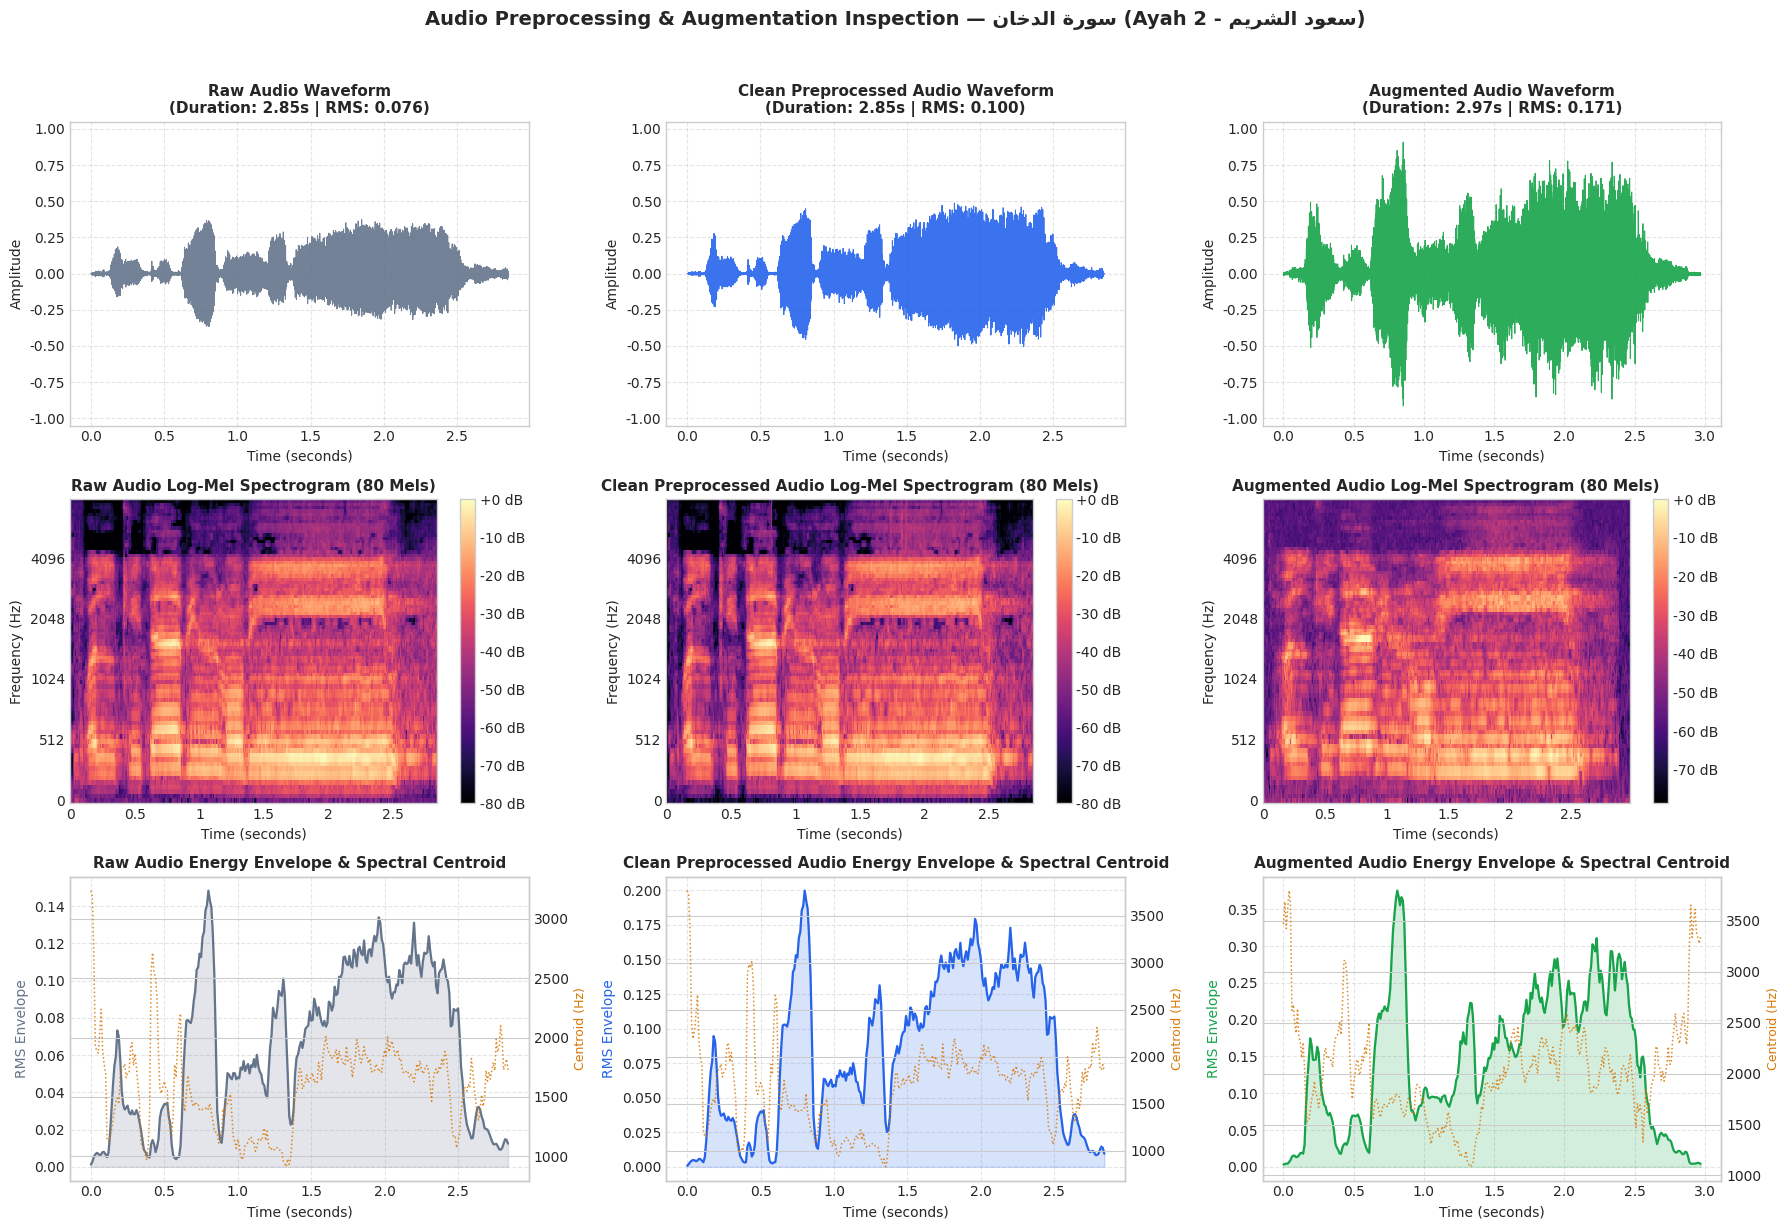

Saved 9-panel waveform, spectrogram & envelope plot to: /content/drive/MyDrive/quran-whisper-dukhan/visualizations/preprocessing_waveform_spectrogram.png


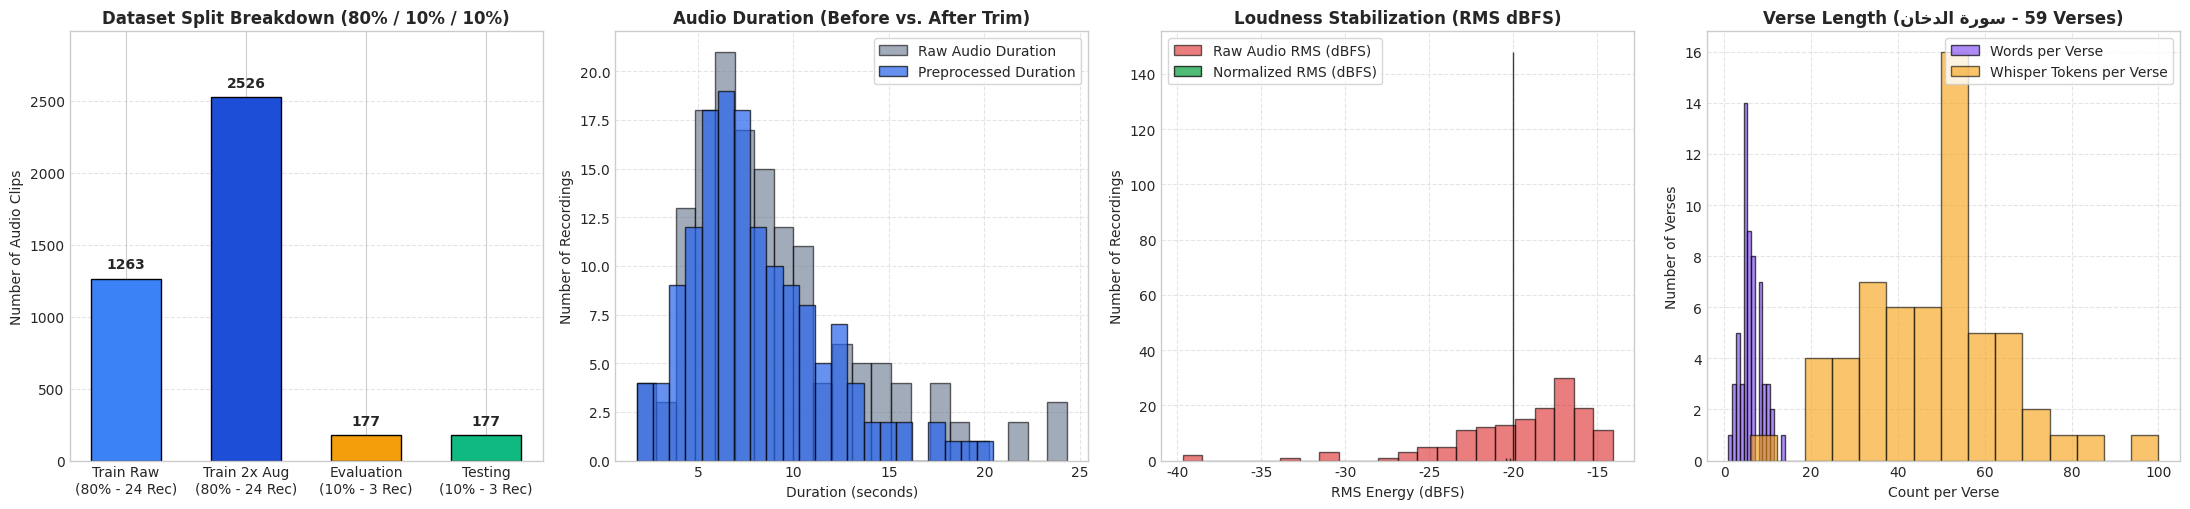

Saved preprocessing & 80/10/10 split distributions plot to: /content/drive/MyDrive/quran-whisper-dukhan/visualizations/preprocessing_distributions.png


In [15]:
import librosa.display
import arabic_reshaper
from bidi.algorithm import get_display
from IPython.display import display, Audio as IPythonAudio, HTML

configure_matplotlib_arabic()

def shape_arabic_for_plot(text):
    """Shapes Arabic text properly for Matplotlib rendering without bracket collisions."""
    if not text:
        return ""
    clean_str = str(text).replace("(", " - ").replace(")", "").strip()
    clean_str = re.sub(r"\s*-\s*-\s*", " - ", clean_str)
    clean_str = re.sub(r"\s+", " ", clean_str).strip(" -")
    return get_display(arabic_reshaper.reshape(clean_str))

def format_reciter_multiline(reciter_ar_text):
    """Splits long Arabic reciter names into two balanced lines so X-axis labels never overlap."""
    clean_str = str(reciter_ar_text).replace("(", "- ").replace(")", "").strip()
    if "-" in clean_str:
        parts = [p.strip() for p in clean_str.split("-", 1)]
        line1 = shape_arabic_for_plot(parts[0])
        line2 = shape_arabic_for_plot(parts[1])
        return f"{line1}\n({line2})"
    words = clean_str.split()
    if len(words) >= 3:
        mid = len(words) // 2
        line1 = shape_arabic_for_plot(" ".join(words[:mid]))
        line2 = shape_arabic_for_plot(" ".join(words[mid:]))
        return f"{line1}\n{line2}"
    return shape_arabic_for_plot(clean_str)

# Pick a representative training example (prefer a full verse rather than the 2-letter opening "حم")
sample_vis_idx = min(10, len(train_audio) - 1)
for candidate_idx in range(min(30, len(train_audio))):
    if train_audio[candidate_idx].get("ayah_id", 1) >= 2:
        sample_vis_idx = candidate_idx
        break

sample_vis = train_audio[sample_vis_idx]
raw_wav = np.asarray(sample_vis["audio"]["array"], dtype=np.float32)
clean_wav = preprocess_clean_waveform(raw_wav, SR)
aug_wav = augment_waveform(clean_wav, SR)

reciter_ar_label = get_arabic_reciter_name(sample_vis)
ayah_num_vis = sample_vis.get("ayah_id", "-")
ayah_text_vis = preprocess_quran_text(sample_vis["ayah_ar"])

print(f"Visualizing Sample -> Surah: {SURAH_NAME_AR} | Verse: {ayah_num_vis} | Reciter: {reciter_ar_label}")
print(f"Quranic Text: {ayah_text_vis}")
print(
    f"Durations -> Raw: {len(raw_wav)/SR:.2f}s | "
    f"Clean Preprocessed: {len(clean_wav)/SR:.2f}s | "
    f"Augmented: {len(aug_wav)/SR:.2f}s"
)

# Display interactive audio players
display(HTML(f"<b>1. Raw Recording ({reciter_ar_label} - {SURAH_NAME_AR} Ayah {ayah_num_vis}):</b>"))
display(IPythonAudio(raw_wav, rate=SR))
display(HTML("<b>2. Clean Preprocessed Recording (Band-pass + Spectral Gate + Trim + Pause Compression + RMS Norm):</b>"))
display(IPythonAudio(clean_wav, rate=SR))
display(HTML("<b>3. Augmented Recording (Time-Stretch + Pitch/Formant Shift + Mosque Reverb + Pink/White SNR Noise):</b>"))
display(IPythonAudio(aug_wav, rate=SR))

# --- Figure 1: 9-Panel Waveform, Log-Mel Spectrogram & RMS/Spectral Centroid Comparison ---
configure_matplotlib_arabic()
fig, axes = plt.subplots(3, 3, figsize=(18, 12))

signals = [
    (raw_wav, "Raw Audio", "#64748b"),
    (clean_wav, "Clean Preprocessed Audio", "#2563eb"),
    (aug_wav, "Augmented Audio", "#16a34a"),
]

for col_idx, (sig, title_prefix, color) in enumerate(signals):
    # Row 1: Waveforms
    t_axis = np.linspace(0, len(sig) / SR, len(sig))
    axes[0, col_idx].plot(t_axis, sig, color=color, linewidth=0.75, alpha=0.9)
    axes[0, col_idx].set_title(
        f"{title_prefix} Waveform\n(Duration: {len(sig)/SR:.2f}s | RMS: {np.sqrt(np.mean(sig**2)):.3f})",
        fontsize=11,
        fontweight="bold",
    )
    axes[0, col_idx].set_xlabel("Time (seconds)", fontsize=10)
    axes[0, col_idx].set_ylabel("Amplitude", fontsize=10)
    axes[0, col_idx].set_ylim(-1.05, 1.05)
    axes[0, col_idx].grid(True, linestyle="--", alpha=0.5)

    # Row 2: Log-Mel Spectrograms (80 Mels)
    mel_spec = librosa.feature.melspectrogram(y=sig, sr=SR, n_mels=80, n_fft=400, hop_length=160)
    mel_db = librosa.power_to_db(mel_spec, ref=np.max)
    img = librosa.display.specshow(
        mel_db,
        sr=SR,
        hop_length=160,
        x_axis="time",
        y_axis="mel",
        ax=axes[1, col_idx],
        cmap="magma",
    )
    axes[1, col_idx].set_title(f"{title_prefix} Log-Mel Spectrogram (80 Mels)", fontsize=11, fontweight="bold")
    axes[1, col_idx].set_xlabel("Time (seconds)", fontsize=10)
    axes[1, col_idx].set_ylabel("Frequency (Hz)", fontsize=10)
    fig.colorbar(img, ax=axes[1, col_idx], format="%+2.0f dB")

    # Row 3: Frame-Level RMS Energy Envelope & Spectral Centroid
    rms_env = librosa.feature.rms(y=sig, frame_length=400, hop_length=160)[0]
    cent = librosa.feature.spectral_centroid(y=sig, sr=SR, n_fft=400, hop_length=160)[0]
    frames_t = librosa.frames_to_time(np.arange(len(rms_env)), sr=SR, hop_length=160)

    ax_env = axes[2, col_idx]
    ax_env.plot(frames_t, rms_env, color=color, linewidth=1.6, label="RMS Energy Envelope")
    ax_env.fill_between(frames_t, 0, rms_env, color=color, alpha=0.18)
    ax_env.set_title(f"{title_prefix} Energy Envelope & Spectral Centroid", fontsize=11, fontweight="bold")
    ax_env.set_xlabel("Time (seconds)", fontsize=10)
    ax_env.set_ylabel("RMS Envelope", fontsize=10, color=color)
    ax_env.grid(True, linestyle="--", alpha=0.5)

    ax_cent = ax_env.twinx()
    ax_cent.plot(frames_t, cent, color="#d97706", linewidth=1.1, linestyle=":", alpha=0.85, label="Spectral Centroid (Hz)")
    ax_cent.set_ylabel("Centroid (Hz)", fontsize=9, color="#d97706")

fig.suptitle(
    f"Audio Preprocessing & Augmentation Inspection — {shape_arabic_for_plot(SURAH_NAME_AR)} "
    f"(Ayah {ayah_num_vis} - {shape_arabic_for_plot(reciter_ar_label)})",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
preproc_wave_plot = os.path.join(PLOTS_DIR, "preprocessing_waveform_spectrogram.png")
plt.savefig(preproc_wave_plot, dpi=150, bbox_inches="tight")
plt.show()
print("Saved 9-panel waveform, spectrogram & envelope plot to:", preproc_wave_plot)

# --- Figure 2: 4-Panel Dataset Split (80/10/10) & Preprocessing Statistical Distributions ---
sample_stat_indices = np.linspace(0, len(train_audio) - 1, min(150, len(train_audio)), dtype=int)
raw_durations, clean_durations = [], []
raw_rms_vals, clean_rms_vals = [], []

for idx in sample_stat_indices:
    arr = np.asarray(train_audio[int(idx)]["audio"]["array"], dtype=np.float32)
    c_arr = preprocess_clean_waveform(arr, SR)
    raw_durations.append(len(arr) / SR)
    clean_durations.append(len(c_arr) / SR)
    raw_rms_vals.append(20.0 * np.log10(np.sqrt(np.mean(arr**2)) + 1e-9))
    clean_rms_vals.append(20.0 * np.log10(np.sqrt(np.mean(c_arr**2)) + 1e-9))

# Compute verse word and token length distributions across all 59 unique verses without decoding audio
unique_verses = {}
for aid, ayah_text in zip(train_raw["ayah_id"], train_raw["ayah_ar"]):
    if aid not in unique_verses:
        unique_verses[aid] = preprocess_quran_text(ayah_text)

verse_word_counts = [len(txt.split()) for txt in unique_verses.values()]
verse_token_counts = [len(processor.tokenizer(txt).input_ids) for txt in unique_verses.values()]

configure_matplotlib_arabic()
fig, axes = plt.subplots(1, 4, figsize=(22, 5.2))

# Panel 1: 80% / 10% / 10% Dataset Split Breakdown (Raw vs. 2x Augmented Train)
split_names = ["Train Raw\n(80% - 24 Rec)", "Train 2x Aug\n(80% - 24 Rec)", "Evaluation\n(10% - 3 Rec)", "Testing\n(10% - 3 Rec)"]
split_counts = [len(train_audio), len(train_audio) * 2, len(eval_audio), len(test_audio)]
split_colors = ["#3b82f6", "#1d4ed8", "#f59e0b", "#10b981"]
bars_sp = axes[0].bar(split_names, split_counts, color=split_colors, edgecolor="black", width=0.58)
axes[0].set_ylim(0, max(split_counts) * 1.18)
axes[0].set_title("Dataset Split Breakdown (80% / 10% / 10%)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Number of Audio Clips", fontsize=10)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)
for bar, cnt in zip(bars_sp, split_counts):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2.0,
        bar.get_height() + max(split_counts) * 0.02,
        f"{cnt}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

# Panel 2: Audio Duration Distribution (Before vs. After Preprocessing)
axes[1].hist(raw_durations, bins=22, alpha=0.6, label="Raw Audio Duration", color="#64748b", edgecolor="black")
axes[1].hist(clean_durations, bins=22, alpha=0.7, label="Preprocessed Duration", color="#2563eb", edgecolor="black")
axes[1].set_title("Audio Duration (Before vs. After Trim)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Duration (seconds)", fontsize=10)
axes[1].set_ylabel("Number of Recordings", fontsize=10)
axes[1].legend(frameon=True)
axes[1].grid(True, linestyle="--", alpha=0.5)

# Panel 3: Loudness (RMS Energy in dBFS) Stabilization
axes[2].hist(raw_rms_vals, bins=22, alpha=0.6, label="Raw Audio RMS (dBFS)", color="#dc2626", edgecolor="black")
axes[2].hist(clean_rms_vals, bins=22, alpha=0.75, label="Normalized RMS (dBFS)", color="#16a34a", edgecolor="black")
axes[2].set_title("Loudness Stabilization (RMS dBFS)", fontsize=12, fontweight="bold")
axes[2].set_xlabel("RMS Energy (dBFS)", fontsize=10)
axes[2].set_ylabel("Number of Recordings", fontsize=10)
axes[2].legend(frameon=True)
axes[2].grid(True, linestyle="--", alpha=0.5)

# Panel 4: Verse Word & Whisper Token Length Distribution across the 59 Verses
axes[3].hist(verse_word_counts, bins=15, alpha=0.7, label="Words per Verse", color="#8b5cf6", edgecolor="black")
axes[3].hist(verse_token_counts, bins=15, alpha=0.6, label="Whisper Tokens per Verse", color="#f59e0b", edgecolor="black")
axes[3].set_title(f"Verse Length ({shape_arabic_for_plot(SURAH_NAME_AR)} - 59 Verses)", fontsize=12, fontweight="bold")
axes[3].set_xlabel("Count per Verse", fontsize=10)
axes[3].set_ylabel("Number of Verses", fontsize=10)
axes[3].legend(frameon=True)
axes[3].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
dist_plot_path = os.path.join(PLOTS_DIR, "preprocessing_distributions.png")
plt.savefig(dist_plot_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved preprocessing & 80/10/10 split distributions plot to:", dist_plot_path)

## Step 10.8 — Extract Whisper Features for Training (80% -> 2x Clean + Augmented), Evaluation (10%), and Testing (10%)

In [16]:
def prepare_clean_example(example):
    """Prepares a clean preprocessed example (deterministic preprocessing without random distortion)."""
    audio = example["audio"]
    clean_wav = preprocess_clean_waveform(audio["array"], audio["sampling_rate"])

    features = processor.feature_extractor(
        clean_wav,
        sampling_rate=audio["sampling_rate"],
    )
    clean_text = preprocess_quran_text(example["ayah_ar"])
    labels = processor.tokenizer(clean_text).input_ids

    return {
        "input_features": features.input_features[0],
        "labels": labels,
    }

def prepare_augmented_example(example):
    """Prepares an augmented training example (deterministic preprocessing + stochastic augmentation)."""
    audio = example["audio"]
    clean_wav = preprocess_clean_waveform(audio["array"], audio["sampling_rate"])
    aug_wav = augment_waveform(clean_wav, audio["sampling_rate"])

    features = processor.feature_extractor(
        aug_wav,
        sampling_rate=audio["sampling_rate"],
    )
    clean_text = preprocess_quran_text(example["ayah_ar"])
    labels = processor.tokenizer(clean_text).input_ids

    return {
        "input_features": features.input_features[0],
        "labels": labels,
    }

# 1. Build Training Dataset (80% split): Concatenate Clean Preprocessed + Augmented copies (2x dataset size)
train_clean_ds = train_audio.map(
    prepare_clean_example,
    remove_columns=train_audio.column_names,
    desc="1/4 Preparing clean preprocessed training audio (80%)",
)

train_aug_ds = train_audio.map(
    prepare_augmented_example,
    remove_columns=train_audio.column_names,
    desc="2/4 Preparing augmented training audio (TimeStretch/Pitch/Formant/Reverb/SNR)",
)

train_dataset = concatenate_datasets([train_clean_ds, train_aug_ds]).shuffle(seed=42)

# 2. Build Evaluation Dataset (10% split): Clean Preprocessed only
eval_dataset = eval_audio.map(
    prepare_clean_example,
    remove_columns=eval_audio.column_names,
    desc="3/4 Preparing clean preprocessed evaluation audio (10%)",
)

# 3. Build Testing Dataset (10% split): Clean Preprocessed only
test_dataset = test_audio.map(
    prepare_clean_example,
    remove_columns=test_audio.column_names,
    desc="4/4 Preparing clean preprocessed testing audio (10%)",
)

print(f"Prepared train_dataset (80% Reciters - Clean + Augmented 2x): {len(train_dataset)} examples")
print(f"Prepared eval_dataset  (10% Reciters - Clean Preprocessed):   {len(eval_dataset)} examples")
print(f"Prepared test_dataset  (10% Reciters - Clean Preprocessed):   {len(test_dataset)} examples")

1/4 Preparing clean preprocessed training audio (80%):   0%|          | 0/1263 [00:00<?, ? examples/s]

2/4 Preparing augmented training audio (TimeStretch/Pitch/Formant/Reverb/SNR):   0%|          | 0/1263 [00:00<…

3/4 Preparing clean preprocessed evaluation audio (10%):   0%|          | 0/177 [00:00<?, ? examples/s]

4/4 Preparing clean preprocessed testing audio (10%):   0%|          | 0/177 [00:00<?, ? examples/s]

Prepared train_dataset (80% Reciters - Clean + Augmented 2x): 2526 examples
Prepared eval_dataset  (10% Reciters - Clean Preprocessed):   177 examples
Prepared test_dataset  (10% Reciters - Clean Preprocessed):   177 examples


## Step 11 — Build Whisper Data Collator

In [17]:
from dataclasses import dataclass
from typing import Any

@dataclass
class WhisperDataCollator:
    processor: Any
    decoder_start_token_id: int

    def __call__(self, features):
        input_features = [
            {"input_features": f["input_features"]}
            for f in features
        ]
        batch = self.processor.feature_extractor.pad(
            input_features,
            return_tensors="pt",
        )

        label_features = [
            {"input_ids": f["labels"]}
            for f in features
        ]
        labels_batch = self.processor.tokenizer.pad(
            label_features,
            return_tensors="pt",
        )

        labels = labels_batch["input_ids"].masked_fill(
            labels_batch["attention_mask"].ne(1),
            -100,
        )

        if (labels[:, 0] == self.decoder_start_token_id).all().cpu().item():
            labels = labels[:, 1:]

        batch["labels"] = labels
        return batch

data_collator = WhisperDataCollator(
    processor=processor,
    decoder_start_token_id=model.config.decoder_start_token_id,
)

## Step 12 — Configure Evaluation Metrics (Normalized & Exact WER and CER)

In [18]:
import jiwer

def normalize_arabic(text):
    """Normalizes Arabic text by stripping diacritics and unifying Alef/Ya forms for lexical WER/CER."""
    text = unicodedata.normalize("NFC", text)
    # Remove Tashkeel, Tatweel, Superscript Alef, and Quranic pause marks for normalized evaluation
    text = re.sub(r"[\u064B-\u065F\u0670\u0640\u06D6-\u06ED]", "", text)
    text = re.sub(r"[إأآٱ]", "ا", text)
    text = text.replace("ى", "ي")
    text = re.sub(r"[^\w\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def compute_metrics(pred):
    pred_ids = pred.predictions
    if isinstance(pred_ids, tuple):
        pred_ids = pred_ids[0]

    label_ids = pred.label_ids.copy()
    label_ids[label_ids == -100] = processor.tokenizer.pad_token_id

    predictions = processor.tokenizer.batch_decode(
        pred_ids,
        skip_special_tokens=True,
    )
    references = processor.tokenizer.batch_decode(
        label_ids,
        skip_special_tokens=True,
    )

    wer_exact = 100.0 * jiwer.wer(references, predictions)
    cer_exact = 100.0 * jiwer.cer(references, predictions)

    norm_refs = [normalize_arabic(r) for r in references]
    norm_preds = [normalize_arabic(p) for p in predictions]

    valid_pairs = [
        (r, p) for r, p in zip(norm_refs, norm_preds) if len(r) > 0
    ]
    if valid_pairs:
        refs_clean = [r for r, _ in valid_pairs]
        preds_clean = [p for _, p in valid_pairs]
        wer_norm = 100.0 * jiwer.wer(refs_clean, preds_clean)
        cer_norm = 100.0 * jiwer.cer(refs_clean, preds_clean)
    else:
        wer_norm = 0.0
        cer_norm = 0.0

    return {
        "wer": round(wer_norm, 2),
        "wer_exact": round(wer_exact, 2),
        "cer": round(cer_norm, 2),
        "cer_exact": round(cer_exact, 2),
    }

## Steps 13 & 14 — Configure Training Arguments and Initialize Seq2SeqTrainer

In [19]:
from transformers import (
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments,
    EarlyStoppingCallback,
)

training_args = Seq2SeqTrainingArguments(
    output_dir=CHECKPOINT_DIR,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=4,
    learning_rate=1e-5,
    warmup_ratio=0.05,
    weight_decay=0.01,
    num_train_epochs=4,
    fp16=True,
    gradient_checkpointing=True,
    eval_strategy="steps",
    save_strategy="steps",
    eval_steps=150,
    save_steps=150,
    logging_steps=25,
    save_total_limit=2,
    predict_with_generate=True,
    generation_max_length=225,
    load_best_model_at_end=True,
    metric_for_best_model="wer",
    greater_is_better=False,
    report_to=["none"],
    remove_unused_columns=False,
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    data_collator=data_collator,
    processing_class=processor,
    compute_metrics=compute_metrics,
    callbacks=[
        EarlyStoppingCallback(early_stopping_patience=3)
    ],
)

print("Seq2SeqTrainer initialized successfully.")

Seq2SeqTrainer initialized successfully.


## Step 15 — Start Training (or Resume Automatically from Latest Checkpoint)

In [20]:
from transformers.trainer_utils import get_last_checkpoint

last_checkpoint = None
if os.path.isdir(CHECKPOINT_DIR):
    last_checkpoint = get_last_checkpoint(CHECKPOINT_DIR)

if last_checkpoint:
    print("Resuming training from checkpoint:", last_checkpoint)
else:
    print("Starting a fresh training run (80/10/10 Reciter Split + Full Preprocessing + 2x Augmentation)...")

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*Trainer.tokenizer is now deprecated.*")
    train_result = trainer.train(resume_from_checkpoint=last_checkpoint)

print("Training summary metrics:", train_result.metrics)

Starting a fresh training run (80/10/10 Reciter Split + Full Preprocessing + 2x Augmentation)...
{'loss': 1.4482, 'grad_norm': 85.7898941040039, 'learning_rate': 3.1746031746031746e-06, 'epoch': 0.0791765637371338}
{'loss': 0.7024, 'grad_norm': 75.59196472167969, 'learning_rate': 7.1428571428571436e-06, 'epoch': 0.1583531274742676}
{'loss': 0.3636, 'grad_norm': 52.627498626708984, 'learning_rate': 9.941520467836257e-06, 'epoch': 0.2375296912114014}
{'loss': 0.2635, 'grad_norm': 52.224632263183594, 'learning_rate': 9.732664995822891e-06, 'epoch': 0.3167062549485352}
{'loss': 0.2522, 'grad_norm': 61.586280822753906, 'learning_rate': 9.523809523809525e-06, 'epoch': 0.39588281868566905}
{'loss': 0.164, 'grad_norm': 36.328243255615234, 'learning_rate': 9.314954051796158e-06, 'epoch': 0.4750593824228028}
{'eval_loss': 0.028653109446167946, 'eval_wer': 4.14, 'eval_wer_exact': 5.97, 'eval_cer': 0.95, 'eval_cer_exact': 1.0, 'eval_runtime': 128.8037, 'eval_samples_per_second': 1.374, 'eval_steps

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:2817: UserWarning: Moving the following attributes in the config to the generation config: {'max_length': 448, 'suppress_tokens': [1, 2, 7, 8, 9, 10, 14, 25, 26, 27, 28, 29, 31, 58, 59, 60, 61, 62, 63, 90, 91, 92, 93, 359, 503, 522, 542, 873, 893, 902, 918, 922, 931, 1350, 1853, 1982, 2460, 2627, 3246, 3253, 3268, 3536, 3846, 3961, 4183, 4667, 6585, 6647, 7273, 9061, 9383, 10428, 10929, 11938, 12033, 12331, 12562, 13793, 14157, 14635, 15265, 15618, 16553, 16604, 18362, 18956, 20075, 21675, 22520, 26130, 26161, 26435, 28279, 29464, 31650, 32302, 32470, 36865, 42863, 47425, 49870, 50254, 50258, 50360, 50361, 50362], 'begin_suppress_tokens': [220, 50257]}. You are seeing this warning because you've set generation parameters in the model config, as opposed to in the generation config.
  warnings.warn(


{'loss': 0.1455, 'grad_norm': 26.42748260498047, 'learning_rate': 9.10609857978279e-06, 'epoch': 0.5542359461599367}
{'loss': 0.1012, 'grad_norm': 18.143688201904297, 'learning_rate': 8.897243107769424e-06, 'epoch': 0.6334125098970704}
{'loss': 0.075, 'grad_norm': 23.4108829498291, 'learning_rate': 8.688387635756056e-06, 'epoch': 0.7125890736342043}
{'loss': 0.0806, 'grad_norm': 11.146258354187012, 'learning_rate': 8.47953216374269e-06, 'epoch': 0.7917656373713381}
{'loss': 0.0615, 'grad_norm': 23.42603302001953, 'learning_rate': 8.270676691729324e-06, 'epoch': 0.8709422011084719}
{'loss': 0.0766, 'grad_norm': 31.911361694335938, 'learning_rate': 8.061821219715958e-06, 'epoch': 0.9501187648456056}
{'eval_loss': 0.005169519688934088, 'eval_wer': 0.87, 'eval_wer_exact': 0.92, 'eval_cer': 0.25, 'eval_cer_exact': 0.24, 'eval_runtime': 126.4935, 'eval_samples_per_second': 1.399, 'eval_steps_per_second': 0.704, 'epoch': 0.9501187648456056}
{'loss': 0.0456, 'grad_norm': 32.673614501953125, 'l

## Step 16 — Save Final Model and Evaluate on Both Validation (10%) and Held-Out Testing (10%) Splits

In [21]:
import os
os.makedirs(FINAL_DIR, exist_ok=True)

trainer.model.config.use_cache = True

trainer.save_model(FINAL_DIR)
processor.save_pretrained(FINAL_DIR)

print("Final model and processor saved to:", FINAL_DIR)

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*Trainer.tokenizer is now deprecated.*")
    final_eval_metrics = trainer.evaluate(eval_dataset=eval_dataset, metric_key_prefix="eval")
    final_test_metrics = trainer.evaluate(eval_dataset=test_dataset, metric_key_prefix="test")

print("\nFinal Validation (10% Split) Metrics:", final_eval_metrics)
print("Final Testing    (10% Split) Metrics:", final_test_metrics)

Final model and processor saved to: /content/drive/MyDrive/quran-whisper-dukhan/final_model_reciter_split
{'eval_loss': 0.00022032986453268677, 'eval_wer': 0.0, 'eval_wer_exact': 0.0, 'eval_cer': 0.0, 'eval_cer_exact': 0.0, 'eval_runtime': 126.0847, 'eval_samples_per_second': 1.404, 'eval_steps_per_second': 0.706, 'epoch': 3.992874109263658}
{'test_loss': 0.0002734981244429946, 'test_wer': 0.0, 'test_wer_exact': 0.0, 'test_cer': 0.0, 'test_cer_exact': 0.0, 'test_runtime': 123.2857, 'test_samples_per_second': 1.436, 'test_steps_per_second': 0.722, 'epoch': 3.992874109263658}

Final Validation (10% Split) Metrics: {'eval_loss': 0.00022032986453268677, 'eval_wer': 0.0, 'eval_wer_exact': 0.0, 'eval_cer': 0.0, 'eval_cer_exact': 0.0, 'eval_runtime': 126.0847, 'eval_samples_per_second': 1.404, 'eval_steps_per_second': 0.706, 'epoch': 3.992874109263658}
Final Testing    (10% Split) Metrics: {'test_loss': 0.0002734981244429946, 'test_wer': 0.0, 'test_wer_exact': 0.0, 'test_cer': 0.0, 'test_cer_

## Step 17 — Single-Verse Inference Test on Unseen Reciter Audio

In [22]:
model = trainer.model
model.eval()

# Select a reciter from the unseen Test (or Evaluation) split and sort by verse number
target_reciter_id = "husary" if "husary" in set(test_audio[reciter_col]).union(set(eval_audio[reciter_col])) else sorted(set(test_audio[reciter_col]))[0]
source_split = test_audio if target_reciter_id in set(test_audio[reciter_col]) else eval_audio
eval_sample_subset = source_split.filter(lambda x: x[reciter_col] == target_reciter_id).sort("ayah_id")

# Test the first 3 verses (Ayah 1, 2, and 3)
for i in range(min(3, len(eval_sample_subset))):
    example = eval_sample_subset[i]
    audio = example["audio"]
    clean_test_wav = preprocess_clean_waveform(audio["array"], audio["sampling_rate"])

    inputs = processor(
        clean_test_wav,
        sampling_rate=audio["sampling_rate"],
        return_tensors="pt",
    ).input_features.to(model.device)

    with torch.no_grad():
        predicted_ids = model.generate(
            inputs,
            max_new_tokens=225,
            language="arabic",
            task="transcribe",
        )

    prediction = processor.batch_decode(
        predicted_ids,
        skip_special_tokens=True,
    )[0]

    print(f"--- Verse Test {i+1} ---")
    print("Surah:", SURAH_NAME_AR)
    print("Reciter:", get_arabic_reciter_name(example))
    print("Verse Number:", example.get("ayah_id", "-"))
    print("Reference Quranic Text:")
    print(preprocess_quran_text(example["ayah_ar"]))
    print("\nPredicted Quranic Text:")
    print(prediction)
    print("\n" + "="*40 + "\n")

Filter:   0%|          | 0/177 [00:00<?, ? examples/s]

--- Verse Test 1 ---
Surah: سورة الدخان
Reciter: محمود خليل الحصري
Verse Number: 1
Reference Quranic Text:
حم

Predicted Quranic Text:
حم


--- Verse Test 2 ---
Surah: سورة الدخان
Reciter: محمود خليل الحصري
Verse Number: 2
Reference Quranic Text:
وَالْكِتَابِ الْمُبِينِ

Predicted Quranic Text:
وَالْكِتَابِ الْمُبِينِ


--- Verse Test 3 ---
Surah: سورة الدخان
Reciter: محمود خليل الحصري
Verse Number: 3
Reference Quranic Text:
إِنَّا أَنزَلْنَاهُ فِي لَيْلَةٍ مُّبَارَكَةٍ ۚ إِنَّا كُنَّا مُنذِرِينَ

Predicted Quranic Text:
إِنَّا أَنزَلْنَاهُ فِي لَيْلَةٍ مُّبَارَكَةٍ ۚ إِنَّا كُنَّا مُنذِرِينَ




In [26]:
model = trainer.model
model.eval()

# Select Muhammad Jibreel from the dataset splits and sort by verse number
target_reciter_id = "muhammad_jibreel"
if target_reciter_id in set(test_audio[reciter_col]):
    source_split = test_audio
elif target_reciter_id in set(eval_audio[reciter_col]):
    source_split = eval_audio
else:
    source_split = train_audio

eval_sample_subset = source_split.filter(lambda x: x[reciter_col] == target_reciter_id).sort("ayah_id")

# Test the first 3 verses (Ayah 1, 2, and 3)
for i in range(min(3, len(eval_sample_subset))):
    example = eval_sample_subset[i]
    audio = example["audio"]
    clean_test_wav = preprocess_clean_waveform(audio["array"], audio["sampling_rate"])

    inputs = processor(
        clean_test_wav,
        sampling_rate=audio["sampling_rate"],
        return_tensors="pt",
    ).input_features.to(model.device)

    with torch.no_grad():
        predicted_ids = model.generate(
            inputs,
            max_new_tokens=225,
            language="arabic",
            task="transcribe",
        )

    prediction = processor.batch_decode(
        predicted_ids,
        skip_special_tokens=True,
    )[0]

    print(f"--- Verse Test {i+1} ---")
    print("Surah:", SURAH_NAME_AR)
    print("Reciter:", get_arabic_reciter_name(example))
    print("Verse Number:", example.get("ayah_id", "-"))
    print("Reference Quranic Text:")
    print(preprocess_quran_text(example["ayah_ar"]))
    print("\nPredicted Quranic Text:")
    print(prediction)
    print("\n" + "="*40 + "\n")

Filter:   0%|          | 0/177 [00:00<?, ? examples/s]

--- Verse Test 1 ---
Surah: سورة الدخان
Reciter: محمد جبريل
Verse Number: 1
Reference Quranic Text:
حم

Predicted Quranic Text:
حم


--- Verse Test 2 ---
Surah: سورة الدخان
Reciter: محمد جبريل
Verse Number: 2
Reference Quranic Text:
وَالْكِتَابِ الْمُبِينِ

Predicted Quranic Text:
وَالْكِتَابِ الْمُبِينِ


--- Verse Test 3 ---
Surah: سورة الدخان
Reciter: محمد جبريل
Verse Number: 3
Reference Quranic Text:
إِنَّا أَنزَلْنَاهُ فِي لَيْلَةٍ مُّبَارَكَةٍ ۚ إِنَّا كُنَّا مُنذِرِينَ

Predicted Quranic Text:
إِنَّا أَنزَلْنَاهُ فِي لَيْلَةٍ مُّبَارَكَةٍ ۚ إِنَّا كُنَّا مُنذِرِينَ




## Step 18 — Transcribe Full Surah Audio Verse-by-Verse for Al-Husary

In [23]:
print("Preparing and transcribing Surah audio for Husary verse by verse...")

husary_dataset = raw_dataset.cast_column("audio", Audio(decode=False))
husary_dataset = husary_dataset.filter(lambda x: x[reciter_col] == "husary").sort("ayah_id")

model = trainer.model
model.eval()

print(f"\nTranscribed Recitation ({SURAH_NAME_AR} - محمود خليل الحصري):\n")
print("="*60)

for row in husary_dataset:
    audio_dict = row["audio"]
    if audio_dict and "bytes" in audio_dict:
        try:
            with io.BytesIO(audio_dict["bytes"]) as f:
                array, sample_rate = sf.read(f)
            if array.ndim > 1:
                array = array.mean(axis=-1)

            if sample_rate != 16000:
                array = librosa.resample(array, orig_sr=sample_rate, target_sr=16000)
                sample_rate = 16000

            clean_wav = preprocess_clean_waveform(array, sample_rate)

            inputs = processor(
                clean_wav,
                sampling_rate=sample_rate,
                return_tensors="pt",
            ).input_features.to(model.device)

            with torch.no_grad():
                predicted_ids = model.generate(
                    inputs,
                    max_new_tokens=225,
                    language="arabic",
                    task="transcribe",
                )

            prediction = processor.batch_decode(
                predicted_ids,
                skip_special_tokens=True,
            )[0]

            print(f"[{row['ayah_id']}] {prediction}")

        except Exception as e:
            print(f"[Error in Ayah {row['ayah_id']}] {e}")

print("="*60)
print("Transcription Complete.")

Preparing and transcribing Surah audio for Husary verse by verse...


Filter:   0%|          | 0/1770 [00:00<?, ? examples/s]


Transcribed Recitation (سورة الدخان - محمود خليل الحصري):

[1] حم
[2] وَالْكِتَابِ الْمُبِينِ
[3] إِنَّا أَنزَلْنَاهُ فِي لَيْلَةٍ مُّبَارَكَةٍ ۚ إِنَّا كُنَّا مُنذِرِينَ
[4] فِيهَا يُفْرَقُ كُلُّ أَمْرٍ حَكِيمٍ
[5] أَمْرًا مِّنْ عِندِنَا ۚ إِنَّا كُنَّا مُرْسِلِينَ
[6] رَحْمَةً مِّن رَّبِّكَ ۚ إِنَّهُ هُوَ السَّمِيعُ الْعَلِيمُ
[7] رَبِّ السَّمَاوَاتِ وَالْأَرْضِ وَمَا بَيْنَهُمَا ۖ إِن كُنتُم مُّوقِنِينَ
[8] لَا إِلَٰهَ إِلَّا هُوَ يُحْيِي وَيُمِيتُ ۖ رَبُّكُمْ وَرَبُّ آبَائِكُمُ الْأَوَّلِينَ
[9] بَلْ هُمْ فِي شَكٍّ يَلْعَبُونَ
[10] فَارْتَقِبْ يَوْمَ تَأْتِي السَّمَاءُ بِدُخَانٍ مُّبِينٍ
[11] يَغْشَى النَّاسَ ۖ هَٰذَا عَذَابٌ أَلِيمٌ
[12] رَّبَّنَا اكْشِفْ عَنَّا الْعَذَابَ إِنَّا مُؤْمِنُونَ
[13] أَنَّىٰ لَهُمُ الذِّكْرَىٰ وَقَدْ جَاءَهُمْ رَسُولٌ مُّبِينٌ
[14] ثُمَّ تَوَلَّوْا عَنْهُ وَقَالُوا مُعَلَّمٌ مَّجْنُونٌ
[15] إِنَّا كَاشِفُو الْعَذَابِ قَلِيلًا ۚ إِنَّكُمْ عَائِدُونَ
[16] يَوْمَ نَبْطِشُ الْبَطْشَةَ الْكُبْرَىٰ إِنَّا مُنتَقِمُونَ
[17] وَلَقَدْ فَتَنَّا قَبْلَهُمْ قَوْ

In [24]:
print("Preparing and transcribing Surah audio for Muhammad Jibreel verse by verse...")

jibreel_dataset = raw_dataset.cast_column("audio", Audio(decode=False))
jibreel_dataset = jibreel_dataset.filter(lambda x: x[reciter_col] == "muhammad_jibreel").sort("ayah_id")

model = trainer.model
model.eval()

print(f"\nTranscribed Recitation ({SURAH_NAME_AR} - محمد جبريل):\n")
print("="*60)

for row in jibreel_dataset:
    audio_dict = row["audio"]
    if audio_dict and "bytes" in audio_dict:
        try:
            with io.BytesIO(audio_dict["bytes"]) as f:
                array, sample_rate = sf.read(f)
            if array.ndim > 1:
                array = array.mean(axis=-1)

            if sample_rate != 16000:
                array = librosa.resample(array, orig_sr=sample_rate, target_sr=16000)
                sample_rate = 16000

            clean_wav = preprocess_clean_waveform(array, sample_rate)

            inputs = processor(
                clean_wav,
                sampling_rate=sample_rate,
                return_tensors="pt",
            ).input_features.to(model.device)

            with torch.no_grad():
                predicted_ids = model.generate(
                    inputs,
                    max_new_tokens=225,
                    language="arabic",
                    task="transcribe",
                )

            prediction = processor.batch_decode(
                predicted_ids,
                skip_special_tokens=True,
            )[0]

            print(f"[{row['ayah_id']}] {prediction}")

        except Exception as e:
            print(f"[Error in Ayah {row['ayah_id']}] {e}")

print("="*60)
print("Transcription Complete.")

Preparing and transcribing Surah audio for Muhammad Jibreel verse by verse...


Filter:   0%|          | 0/1770 [00:00<?, ? examples/s]


Transcribed Recitation (سورة الدخان - محمد جبريل):

[1] حم
[2] وَالْكِتَابِ الْمُبِينِ
[3] إِنَّا أَنزَلْنَاهُ فِي لَيْلَةٍ مُّبَارَكَةٍ ۚ إِنَّا كُنَّا مُنذِرِينَ
[4] فِيهَا يُفْرَقُ كُلُّ أَمْرٍ حَكِيمٍ
[5] أَمْرًا مِّنْ عِندِنَا ۚ إِنَّا كُنَّا مُرْسِلِينَ
[6] رَحْمَةً مِّن رَّبِّكَ ۚ إِنَّهُ هُوَ السَّمِيعُ الْعَلِيمُ
[7] رَبِّ السَّمَاوَاتِ وَالْأَرْضِ وَمَا بَيْنَهُمَا ۖ إِن كُنتُم مُّوقِنِينَ
[8] لَا إِلَٰهَ إِلَّا هُوَ يُحْيِي وَيُمِيتُ ۖ رَبُّكُمْ وَرَبُّ آبَائِكُمُ الْأَوَّلِينَ
[9] بَلْ هُمْ فِي شَكٍّ يَلْعَبُونَ
[10] فَارْتَقِبْ يَوْمَ تَأْتِي السَّمَاءُ بِدُخَانٍ مُّبِينٍ
[11] يَغْشَى النَّاسَ ۖ هَٰذَا عَذَابٌ أَلِيمٌ
[12] رَّبَّنَا اكْشِفْ عَنَّا الْعَذَابَ إِنَّا مُؤْمِنُونَ
[13] أَنَّىٰ لَهُمُ الذِّكْرَىٰ وَقَدْ جَاءَهُمْ رَسُولٌ مُّبِينٌ
[14] ثُمَّ تَوَلَّوْا عَنْهُ وَقَالُوا مُعَلَّمٌ مَّجْنُونٌ
[15] إِنَّا كَاشِفُو الْعَذَابِ قَلِيلًا ۚ إِنَّكُمْ عَائِدُونَ
[16] يَوْمَ نَبْطِشُ الْبَطْشَةَ الْكُبْرَىٰ إِنَّا مُنتَقِمُونَ
[17] وَلَقَدْ فَتَنَّا قَبْلَهُمْ قَوْمَ فِرْ

## Step 19 — Comprehensive Results & Metrics Visualization Suite (Evaluation 10% + Testing 10%)
This cell produces four publication-ready visualization dashboards and interactive comparison tables with zero font or deprecation warnings:
1. **Dashboard 1 (4-Panel Training Progression):**
   - Training Loss vs. Validation Loss over steps
   - Normalized WER vs. Exact WER progression
   - Normalized CER vs. Exact CER progression
   - Learning Rate Schedule & Gradient Norm stability
2. **Dashboard 2 (Validation 10% vs. Testing 10% Split Comparison & Error-Type Diagnostics):**
   - Side-by-Side Bar Comparison of Validation (10%) vs. Testing (10%) Metrics (`Normalized WER`, `Exact WER`, `Normalized CER`, `Exact CER`)
   - Per-Reciter Error Rates across all 6 Unseen Reciters (3 Evaluation + 3 Testing)
   - Word-Level Alignment Breakdown (Correct Hits, Substitutions, Deletions, Insertions)
3. **Dashboard 3 (Verse Length vs. Error Scatter & Per-Verse WER Distribution)**
4. **Dashboard 4 (Diverse Sample Predictions Comparison Chart & Styled HTML Table)**

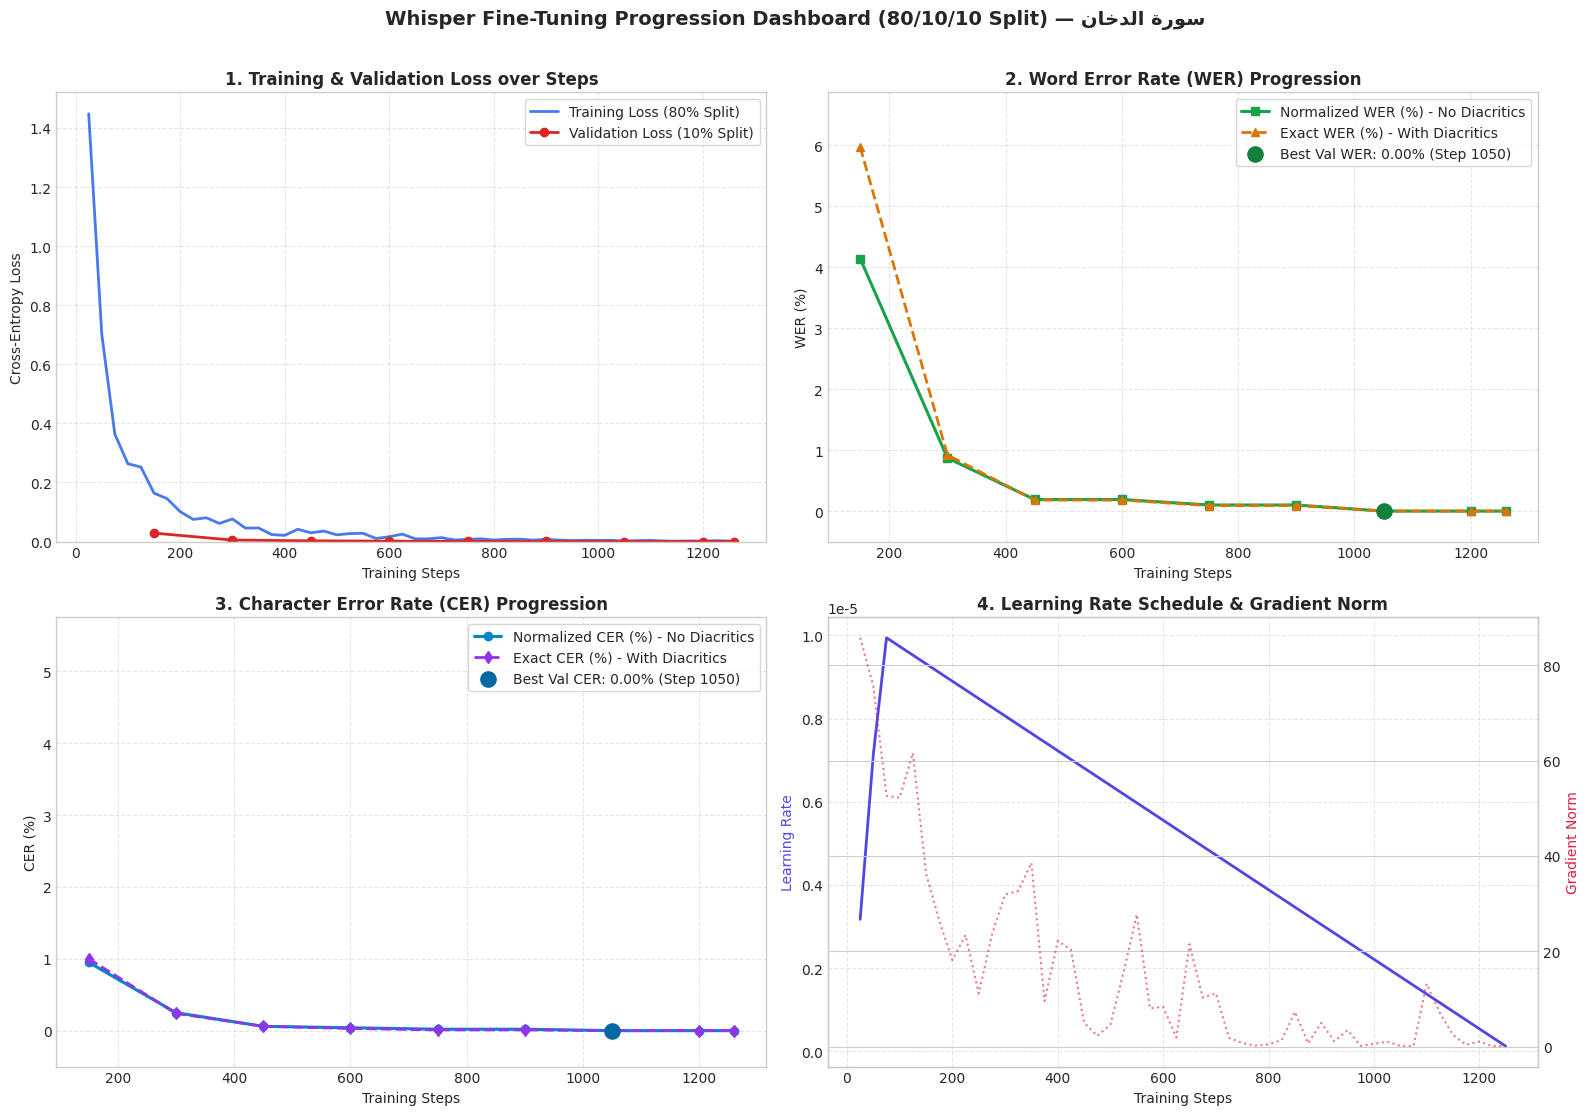

Saved 4-panel training progression dashboard to: /content/drive/MyDrive/quran-whisper-dukhan/visualizations/training_progression_dashboard.png
Running full evaluation diagnostics across Evaluation (10%) and Testing (10%) splits...


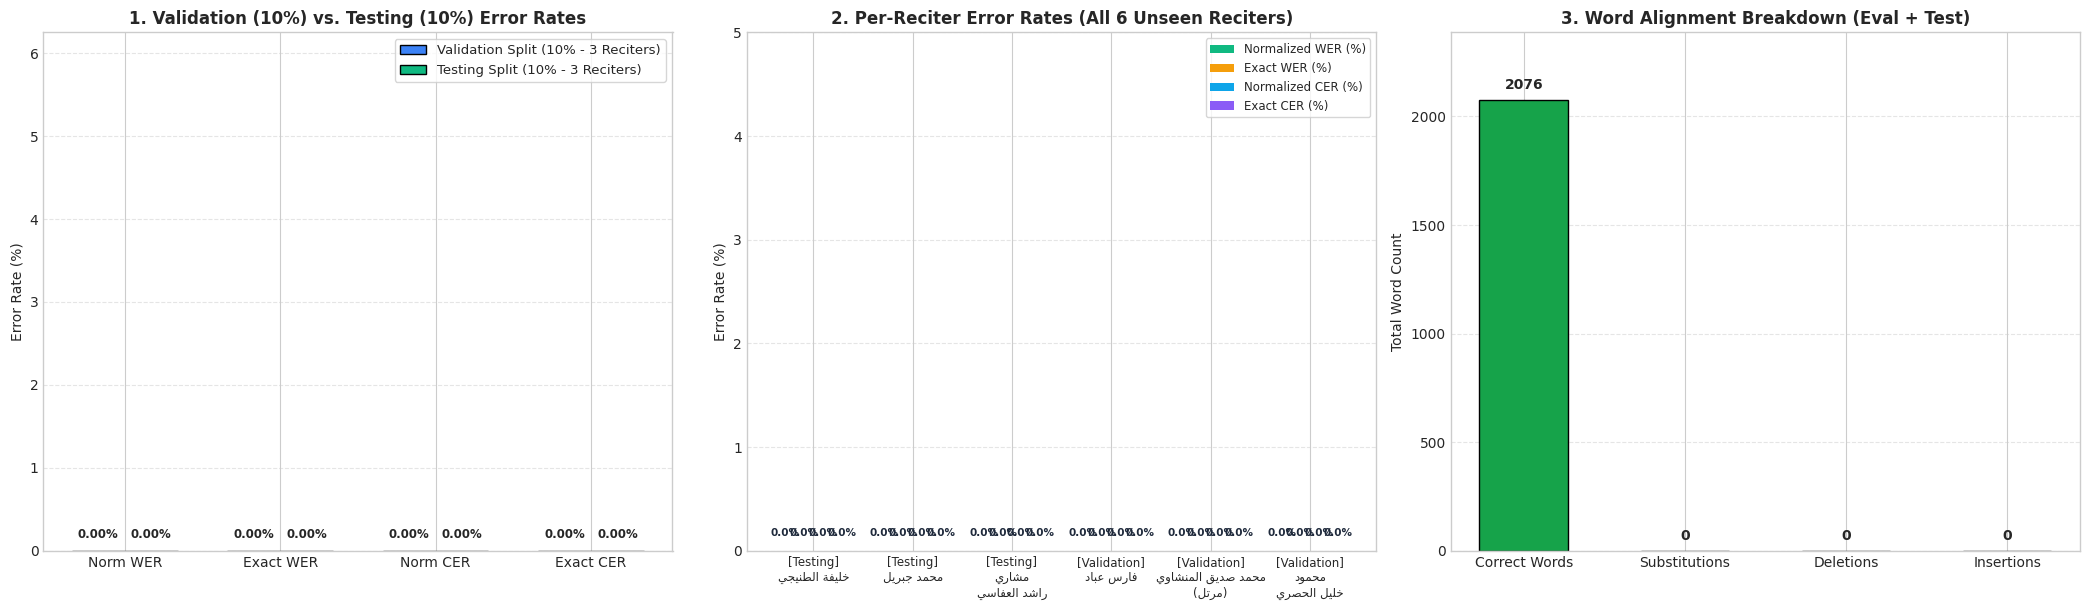

Saved validation & testing diagnostics dashboard to: /content/drive/MyDrive/quran-whisper-dukhan/visualizations/evaluation_and_testing_diagnostics_dashboard.png


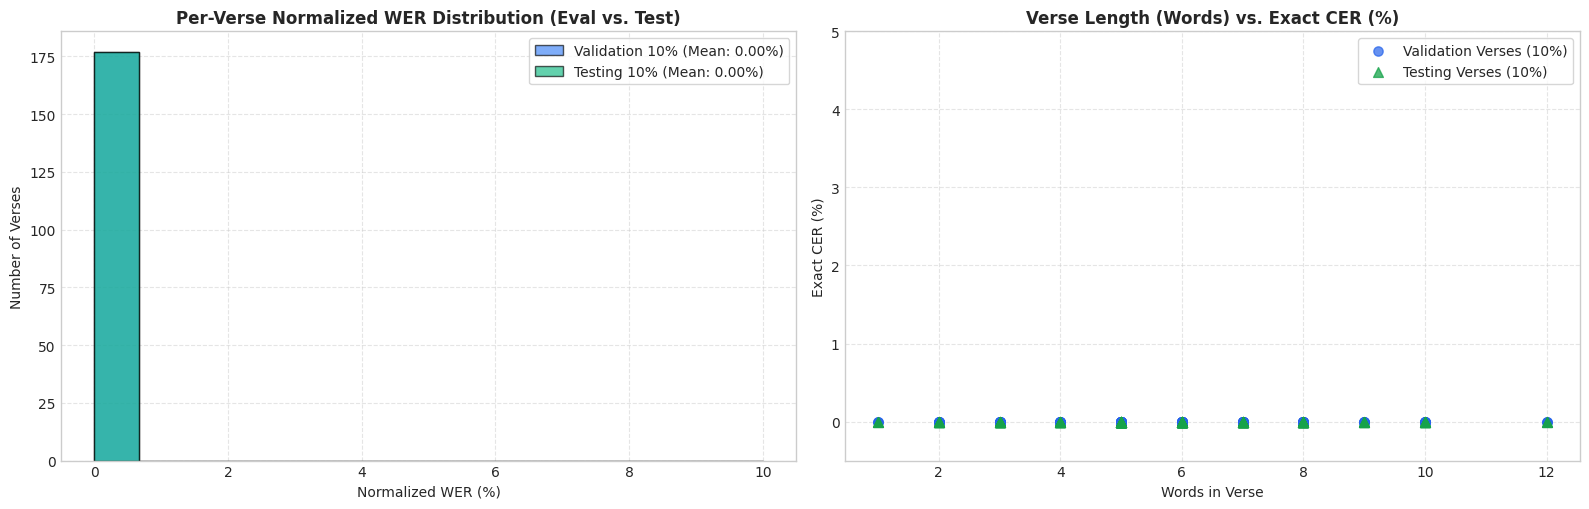

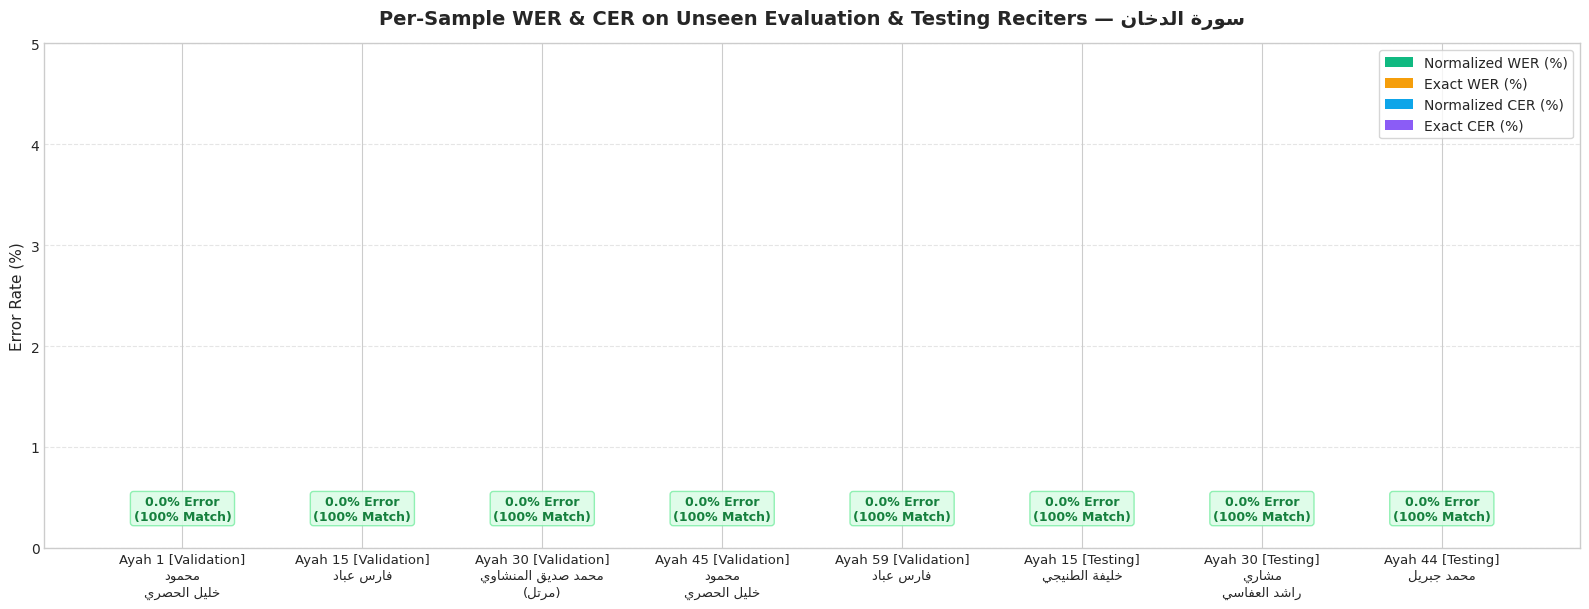

Saved per-sample comparison chart to: /content/drive/MyDrive/quran-whisper-dukhan/visualizations/sample_predictions_comparison.png


,Split,Surah,Ayah ID,Reciter,Reference Text,Predicted Text,Normalized WER (%),Exact WER (%),Normalized CER (%),Exact CER (%)
0,Validation (10%),سورة الدخان,1,محمود خليل الحصري,حم,حم,0.000000,0.000000,0.000000,0.000000
44,Validation (10%),سورة الدخان,15,فارس عباد,إِنَّا كَاشِفُو الْعَذَابِ قَلِيلًا ۚ إِنَّكُمْ عَائِدُونَ,إِنَّا كَاشِفُو الْعَذَابِ قَلِيلًا ۚ إِنَّكُمْ عَائِدُونَ,0.000000,0.000000,0.000000,0.000000
88,Validation (10%),سورة الدخان,30,محمد صديق المنشاوي - مرتل,وَلَقَدْ نَجَّيْنَا بَنِي إِسْرَائِيلَ مِنَ الْعَذَابِ الْمُهِينِ,وَلَقَدْ نَجَّيْنَا بَنِي إِسْرَائِيلَ مِنَ الْعَذَابِ الْمُهِينِ,0.000000,0.000000,0.000000,0.000000
132,Validation (10%),سورة الدخان,45,محمود خليل الحصري,كَالْمُهْلِ يَغْلِي فِي الْبُطُونِ,كَالْمُهْلِ يَغْلِي فِي الْبُطُونِ,0.000000,0.000000,0.000000,0.000000
176,Validation (10%),سورة الدخان,59,فارس عباد,فَارْتَقِبْ إِنَّهُم مُّرْتَقِبُونَ,فَارْتَقِبْ إِنَّهُم مُّرْتَقِبُونَ,0.000000,0.000000,0.000000,0.000000
220,Testing (10%),سورة الدخان,15,خليفة الطنيجي,إِنَّا كَاشِفُو الْعَذَابِ قَلِيلًا ۚ إِنَّكُمْ عَائِدُونَ,إِنَّا كَاشِفُو الْعَذَابِ قَلِيلًا ۚ إِنَّكُمْ عَائِدُونَ,0.000000,0.000000,0.000000,0.000000
264,Testing (10%),سورة الدخان,30,مشاري راشد العفاسي,وَلَقَدْ نَجَّيْنَا بَنِي إِسْرَائِيلَ مِنَ الْعَذَابِ الْمُهِينِ,وَلَقَدْ نَجَّيْنَا بَنِي إِسْرَائِيلَ مِنَ الْعَذَابِ الْمُهِينِ,0.000000,0.000000,0.000000,0.000000
308,Testing (10%),سورة الدخان,44,محمد جبريل,طَعَامُ الْأَثِيمِ,طَعَامُ الْأَثِيمِ,0.000000,0.000000,0.000000,0.000000


In [25]:
import json
import pandas as pd

# Silence all deprecation and font warnings inside the visualization cell
warnings.filterwarnings("ignore", message=".*Trainer.tokenizer is now deprecated.*")
warnings.filterwarnings("ignore", message=".*Glyph .* missing from font.*")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
hf_logging.set_verbosity_error()
configure_matplotlib_arabic()

# 1. Extract training log history from active trainer or latest saved checkpoint on Drive
log_history = []
if "trainer" in globals() and hasattr(trainer, "state") and trainer.state.log_history:
    log_history = trainer.state.log_history
else:
    state_files = sorted(glob.glob(os.path.join(CHECKPOINT_DIR, "checkpoint-*", "trainer_state.json")))
    if state_files:
        with open(state_files[-1], "r", encoding="utf-8") as f:
            log_history = json.load(f).get("log_history", [])

train_steps, train_losses, grad_norms, lrs = [], [], [], []
eval_steps, eval_losses = [], []
eval_wers, eval_wers_exact = [], []
eval_cers, eval_cers_exact = [], []

for entry in log_history:
    if "loss" in entry and "eval_loss" not in entry and "test_loss" not in entry:
        train_steps.append(entry["step"])
        train_losses.append(entry["loss"])
        grad_norms.append(entry.get("grad_norm", None))
        lrs.append(entry.get("learning_rate", None))
    if "eval_loss" in entry:
        eval_steps.append(entry["step"])
        eval_losses.append(entry["eval_loss"])
        eval_wers.append(entry.get("eval_wer", None))
        eval_wers_exact.append(entry.get("eval_wer_exact", None))
        eval_cers.append(entry.get("eval_cer", None))
        eval_cers_exact.append(entry.get("eval_cer_exact", None))

# --- Dashboard 1: 4-Panel Training & Validation Progression ---
configure_matplotlib_arabic()
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Panel 1: Loss Curve
if train_steps:
    axes[0, 0].plot(train_steps, train_losses, label="Training Loss (80% Split)", color="#2563eb", linewidth=2, alpha=0.85)
if eval_steps:
    axes[0, 0].plot(eval_steps, eval_losses, label="Validation Loss (10% Split)", color="#dc2626", marker="o", linewidth=2)
axes[0, 0].set_title("1. Training & Validation Loss over Steps", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Training Steps", fontsize=10)
axes[0, 0].set_ylabel("Cross-Entropy Loss", fontsize=10)
axes[0, 0].set_ylim(bottom=0)
axes[0, 0].legend(frameon=True)
axes[0, 0].grid(True, linestyle="--", alpha=0.5)

# Panel 2: WER Progression
if eval_steps and any(w is not None for w in eval_wers):
    axes[0, 1].plot(
        eval_steps, eval_wers,
        label="Normalized WER (%) - No Diacritics",
        color="#16a34a", marker="s", linewidth=2.2
    )
    axes[0, 1].plot(
        eval_steps, eval_wers_exact,
        label="Exact WER (%) - With Diacritics",
        color="#d97706", marker="^", linewidth=2, linestyle="--"
    )
    best_idx = int(np.argmin(eval_wers))
    axes[0, 1].scatter(
        [eval_steps[best_idx]], [eval_wers[best_idx]],
        color="#15803d", s=120, zorder=5,
        label=f"Best Val WER: {eval_wers[best_idx]:.2f}% (Step {eval_steps[best_idx]})"
    )
    max_wer_plot = max([w for w in (eval_wers + eval_wers_exact) if w is not None] + [5.0])
    axes[0, 1].set_ylim(-0.5, max(5.0, max_wer_plot * 1.15))
axes[0, 1].set_title("2. Word Error Rate (WER) Progression", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Training Steps", fontsize=10)
axes[0, 1].set_ylabel("WER (%)", fontsize=10)
axes[0, 1].legend(frameon=True)
axes[0, 1].grid(True, linestyle="--", alpha=0.5)

# Panel 3: CER Progression
if eval_steps and any(c is not None for c in eval_cers):
    axes[1, 0].plot(
        eval_steps, eval_cers,
        label="Normalized CER (%) - No Diacritics",
        color="#0284c7", marker="o", linewidth=2.2
    )
    axes[1, 0].plot(
        eval_steps, eval_cers_exact,
        label="Exact CER (%) - With Diacritics",
        color="#9333ea", marker="d", linewidth=2, linestyle="--"
    )
    best_cer_idx = int(np.argmin(eval_cers))
    axes[1, 0].scatter(
        [eval_steps[best_cer_idx]], [eval_cers[best_cer_idx]],
        color="#0369a1", s=120, zorder=5,
        label=f"Best Val CER: {eval_cers[best_cer_idx]:.2f}% (Step {eval_steps[best_cer_idx]})"
    )
    max_cer_plot = max([c for c in (eval_cers + eval_cers_exact) if c is not None] + [5.0])
    axes[1, 0].set_ylim(-0.5, max(5.0, max_cer_plot * 1.15))
axes[1, 0].set_title("3. Character Error Rate (CER) Progression", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Training Steps", fontsize=10)
axes[1, 0].set_ylabel("CER (%)", fontsize=10)
axes[1, 0].legend(frameon=True)
axes[1, 0].grid(True, linestyle="--", alpha=0.5)

# Panel 4: Learning Rate & Gradient Norm Stability
ax_lr = axes[1, 1]
if train_steps and any(l is not None for l in lrs):
    ax_lr.plot(train_steps, lrs, label="Learning Rate", color="#4f46e5", linewidth=2)
ax_lr.set_title("4. Learning Rate Schedule & Gradient Norm", fontsize=12, fontweight="bold")
ax_lr.set_xlabel("Training Steps", fontsize=10)
ax_lr.set_ylabel("Learning Rate", fontsize=10, color="#4f46e5")
ax_lr.grid(True, linestyle="--", alpha=0.5)

if train_steps and any(g is not None for g in grad_norms):
    ax_gn = ax_lr.twinx()
    valid_gn = [(s, g) for s, g in zip(train_steps, grad_norms) if g is not None]
    if valid_gn:
        gn_steps, gn_vals = zip(*valid_gn)
        ax_gn.plot(gn_steps, gn_vals, label="Gradient Norm", color="#e11d48", linewidth=1.5, alpha=0.6, linestyle=":")
        ax_gn.set_ylabel("Gradient Norm", fontsize=10, color="#e11d48")

fig.suptitle(
    f"Whisper Fine-Tuning Progression Dashboard (80/10/10 Split) — {shape_arabic_for_plot(SURAH_NAME_AR)}",
    fontsize=14,
    fontweight="bold",
    y=1.01,
)
plt.tight_layout()
dashboard1_path = os.path.join(PLOTS_DIR, "training_progression_dashboard.png")
plt.savefig(dashboard1_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved 4-panel training progression dashboard to:", dashboard1_path)

# --- 2. Run Full Prediction Pass on Both Evaluation (10%) and Testing (10%) Splits ---
print("Running full evaluation diagnostics across Evaluation (10%) and Testing (10%) splits...")

def collect_split_diagnostics(split_dataset, split_audio, split_label):
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message=".*Trainer.tokenizer is now deprecated.*")
        pred_out = trainer.predict(split_dataset)

    p_ids = pred_out.predictions
    if isinstance(p_ids, tuple):
        p_ids = p_ids[0]

    preds = [p.strip() for p in processor.tokenizer.batch_decode(p_ids, skip_special_tokens=True)]
    ayah_ids = split_audio["ayah_id"]
    rec_ids = split_audio[reciter_col]
    rec_ars = split_audio["reciter_ar"] if "reciter_ar" in split_audio.column_names else [None] * len(split_audio)
    refs = [preprocess_quran_text(txt) for txt in split_audio["ayah_ar"]]

    records = []
    hits, subs, dels, ins = 0, 0, 0, 0

    for idx, (ref_text, pred_text) in enumerate(zip(refs, preds)):
        rec_ar = rec_ars[idx] if rec_ars[idx] else get_arabic_reciter_name(rec_ids[idx])
        ayah_id = ayah_ids[idx]

        norm_ref = normalize_arabic(ref_text)
        norm_pred = normalize_arabic(pred_text)

        w_norm = 100.0 * jiwer.wer(norm_ref, norm_pred) if norm_ref else 0.0
        w_exact = 100.0 * jiwer.wer(ref_text, pred_text) if ref_text else 0.0
        c_norm = 100.0 * jiwer.cer(norm_ref, norm_pred) if norm_ref else 0.0
        c_exact = 100.0 * jiwer.cer(ref_text, pred_text) if ref_text else 0.0

        if norm_ref:
            word_out = jiwer.process_words(norm_ref, norm_pred)
            hits += word_out.hits
            subs += word_out.substitutions
            dels += word_out.deletions
            ins += word_out.insertions

        records.append({
            "Split": split_label,
            "Surah": SURAH_NAME_AR,
            "Ayah ID": ayah_id,
            "Reciter": rec_ar,
            "Word Count": len(norm_ref.split()) if norm_ref else 0,
            "Reference Text": ref_text,
            "Predicted Text": pred_text,
            "Normalized WER (%)": round(w_norm, 2),
            "Exact WER (%)": round(w_exact, 2),
            "Normalized CER (%)": round(c_norm, 2),
            "Exact CER (%)": round(c_exact, 2),
        })

    return pd.DataFrame(records), (hits, subs, dels, ins)

eval_df, eval_align = collect_split_diagnostics(eval_dataset, eval_audio, "Validation (10%)")
test_df, test_align = collect_split_diagnostics(test_dataset, test_audio, "Testing (10%)")
combined_unseen_df = pd.concat([eval_df, test_df], ignore_index=True)

total_hits = eval_align[0] + test_align[0]
total_subs = eval_align[1] + test_align[1]
total_dels = eval_align[2] + test_align[2]
total_ins  = eval_align[3] + test_align[3]

# --- Dashboard 2: Validation (10%) vs. Testing (10%) Comparison, Per-Reciter Breakdown & Word Alignment ---
configure_matplotlib_arabic()
fig, axes = plt.subplots(1, 3, figsize=(21, 6.2))

# Panel 1: Validation (10%) vs. Testing (10%) Split Metrics Comparison
metric_cols = ["Normalized WER (%)", "Exact WER (%)", "Normalized CER (%)", "Exact CER (%)"]
val_means = [eval_df[c].mean() for c in metric_cols]
tst_means = [test_df[c].mean() for c in metric_cols]
x_m = np.arange(len(metric_cols))
mw = 0.34

mb1 = axes[0].bar(x_m - mw / 2, val_means, mw, label="Validation Split (10% - 3 Reciters)", color="#3b82f6", edgecolor="black")
mb2 = axes[0].bar(x_m + mw / 2, tst_means, mw, label="Testing Split (10% - 3 Reciters)", color="#10b981", edgecolor="black")
max_split_err = max(val_means + tst_means + [5.0])
axes[0].set_ylim(0.0, max(5.0, max_split_err * 1.25))
axes[0].set_title("1. Validation (10%) vs. Testing (10%) Error Rates", fontsize=12, fontweight="bold")
axes[0].set_xticks(x_m)
axes[0].set_xticklabels(["Norm WER", "Exact WER", "Norm CER", "Exact CER"], fontsize=10)
axes[0].set_ylabel("Error Rate (%)", fontsize=10)
axes[0].legend(frameon=True, fontsize=9.5)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

for bar_g in (mb1, mb2):
    for bar in bar_g:
        val = bar.get_height()
        axes[0].text(
            bar.get_x() + bar.get_width() / 2.0,
            val + 0.12,
            f"{val:.2f}%",
            ha="center",
            va="bottom",
            fontsize=8.5,
            fontweight="bold",
        )

# Panel 2: Per-Reciter Error Rates Across All 6 Held-Out Unseen Reciters (Validation + Testing)
reciter_group = combined_unseen_df.groupby(["Split", "Reciter"])[metric_cols].mean().reset_index()
rec_labels_shaped = [
    f"[{row['Split'].split()[0]}]\n{format_reciter_multiline(row['Reciter'])}"
    for _, row in reciter_group.iterrows()
]
x_rec = np.arange(len(reciter_group))
bw = 0.19

b1 = axes[1].bar(x_rec - 1.5 * bw, reciter_group["Normalized WER (%)"], bw, label="Normalized WER (%)", color="#10b981")
b2 = axes[1].bar(x_rec - 0.5 * bw, reciter_group["Exact WER (%)"], bw, label="Exact WER (%)", color="#f59e0b")
b3 = axes[1].bar(x_rec + 0.5 * bw, reciter_group["Normalized CER (%)"], bw, label="Normalized CER (%)", color="#0ea5e9")
b4 = axes[1].bar(x_rec + 1.5 * bw, reciter_group["Exact CER (%)"], bw, label="Exact CER (%)", color="#8b5cf6")

max_rec_err = float(reciter_group[metric_cols].values.max()) if len(reciter_group) > 0 else 0.0
axes[1].set_ylim(0.0, max(5.0, max_rec_err * 1.25))
axes[1].set_title("2. Per-Reciter Error Rates (All 6 Unseen Reciters)", fontsize=12, fontweight="bold")
axes[1].set_xticks(x_rec)
axes[1].set_xticklabels(rec_labels_shaped, fontsize=8.5, linespacing=1.25)
axes[1].set_ylabel("Error Rate (%)", fontsize=10)
axes[1].legend(frameon=True, fontsize=8.5, loc="upper right")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

for bar_group in (b1, b2, b3, b4):
    for bar in bar_group:
        val = bar.get_height()
        axes[1].text(
            bar.get_x() + bar.get_width() / 2.0,
            val + 0.12,
            f"{val:.1f}%",
            ha="center",
            va="bottom",
            fontsize=7.5,
            fontweight="bold",
            color="#1e293b",
        )

# Panel 3: Word-Level Alignment Breakdown (Correct Hits vs. Substitutions vs. Deletions vs. Insertions)
align_categories = ["Correct Words", "Substitutions", "Deletions", "Insertions"]
align_counts = [total_hits, total_subs, total_dels, total_ins]
align_colors = ["#16a34a", "#f59e0b", "#dc2626", "#9333ea"]

bars = axes[2].bar(align_categories, align_counts, color=align_colors, edgecolor="black", width=0.55)
axes[2].set_ylim(0, max(10, int(max(align_counts) * 1.15)))
axes[2].set_title("3. Word Alignment Breakdown (Eval + Test)", fontsize=12, fontweight="bold")
axes[2].set_ylabel("Total Word Count", fontsize=10)
axes[2].grid(axis="y", linestyle="--", alpha=0.5)
for bar, count in zip(bars, align_counts):
    axes[2].text(
        bar.get_x() + bar.get_width() / 2.0,
        bar.get_height() + max(1, 0.018 * max(align_counts)),
        f"{count}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

plt.tight_layout()
dashboard2_path = os.path.join(PLOTS_DIR, "evaluation_and_testing_diagnostics_dashboard.png")
plt.savefig(dashboard2_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved validation & testing diagnostics dashboard to:", dashboard2_path)

# --- Dashboard 3: Verse Length vs. Error Scatter & Per-Verse WER Histogram ---
configure_matplotlib_arabic()
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))

# Panel 1: Per-Verse Normalized WER Distribution (Validation vs. Testing)
max_hist_wer = max(10.0, float(combined_unseen_df["Normalized WER (%)"].max()) + 1.0)
axes[0].hist(
    eval_df["Normalized WER (%)"],
    bins=15,
    range=(0, max_hist_wer),
    color="#3b82f6",
    alpha=0.65,
    edgecolor="black",
    label=f"Validation 10% (Mean: {eval_df['Normalized WER (%)'].mean():.2f}%)",
)
axes[0].hist(
    test_df["Normalized WER (%)"],
    bins=15,
    range=(0, max_hist_wer),
    color="#10b981",
    alpha=0.65,
    edgecolor="black",
    label=f"Testing 10% (Mean: {test_df['Normalized WER (%)'].mean():.2f}%)",
)
axes[0].set_title("Per-Verse Normalized WER Distribution (Eval vs. Test)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Normalized WER (%)", fontsize=10)
axes[0].set_ylabel("Number of Verses", fontsize=10)
axes[0].legend(frameon=True)
axes[0].grid(True, linestyle="--", alpha=0.5)

# Panel 2: Verse Word Count vs. Exact CER Scatter
axes[1].scatter(
    eval_df["Word Count"],
    eval_df["Exact CER (%)"],
    color="#2563eb",
    alpha=0.7,
    s=45,
    label="Validation Verses (10%)",
)
axes[1].scatter(
    test_df["Word Count"],
    test_df["Exact CER (%)"],
    color="#16a34a",
    marker="^",
    alpha=0.75,
    s=50,
    label="Testing Verses (10%)",
)
axes[1].set_ylim(-0.5, max(5.0, float(combined_unseen_df["Exact CER (%)"].max()) * 1.2))
axes[1].set_title("Verse Length (Words) vs. Exact CER (%)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Words in Verse", fontsize=10)
axes[1].set_ylabel("Exact CER (%)", fontsize=10)
axes[1].legend(frameon=True)
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
dashboard3_path = os.path.join(PLOTS_DIR, "verse_length_vs_error_dashboard.png")
plt.savefig(dashboard3_path, dpi=150, bbox_inches="tight")
plt.show()

# Display Per-Reciter Summary Table Across Both Held-Out Splits
display(HTML("<h3>Per-Reciter Summary Metrics on Unseen Validation (10%) & Testing (10%) Voices:</h3>"))
display(
    reciter_group.set_index(["Split", "Reciter"]).round(2).style.background_gradient(cmap="YlOrRd", vmin=0, vmax=100)
)

# --- Dashboard 4: Diverse Sample Predictions Chart & Styled Comparison Table (From Testing & Validation) ---
num_samples = min(8, len(combined_unseen_df))
step_stride = max(1, len(combined_unseen_df) // num_samples)
sample_indices = [i * step_stride for i in range(num_samples)]
samples_df = combined_unseen_df.iloc[sample_indices].copy()

configure_matplotlib_arabic()
fig, ax = plt.subplots(figsize=(16, 6.2))
x_pos = np.arange(len(samples_df))
bar_w = 0.19

x_tick_labels = [
    f"Ayah {row['Ayah ID']} [{row['Split'].split()[0]}]\n{format_reciter_multiline(row['Reciter'])}"
    for _, row in samples_df.iterrows()
]

sb1 = ax.bar(x_pos - 1.5 * bar_w, samples_df["Normalized WER (%)"], bar_w, label="Normalized WER (%)", color="#10b981")
sb2 = ax.bar(x_pos - 0.5 * bar_w, samples_df["Exact WER (%)"], bar_w, label="Exact WER (%)", color="#f59e0b")
sb3 = ax.bar(x_pos + 0.5 * bar_w, samples_df["Normalized CER (%)"], bar_w, label="Normalized CER (%)", color="#0ea5e9")
sb4 = ax.bar(x_pos + 1.5 * bar_w, samples_df["Exact CER (%)"], bar_w, label="Exact CER (%)", color="#8b5cf6")

max_sample_err = float(
    samples_df[["Normalized WER (%)", "Exact WER (%)", "Normalized CER (%)", "Exact CER (%)"]].values.max()
)
ax.set_ylim(0.0, max(5.0, max_sample_err * 1.25))

for idx_pos in range(len(samples_df)):
    row_vals = [
        samples_df.iloc[idx_pos]["Normalized WER (%)"],
        samples_df.iloc[idx_pos]["Exact WER (%)"],
        samples_df.iloc[idx_pos]["Normalized CER (%)"],
        samples_df.iloc[idx_pos]["Exact CER (%)"],
    ]
    if max(row_vals) == 0.0:
        ax.text(
            x_pos[idx_pos],
            0.25,
            "0.0% Error\n(100% Match)",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
            color="#15803d",
            bbox=dict(boxstyle="round,pad=0.25", facecolor="#dcfce7", edgecolor="#86efac", alpha=0.9),
        )
    else:
        for b_grp in (sb1, sb2, sb3, sb4):
            bar = b_grp[idx_pos]
            val = bar.get_height()
            ax.text(
                bar.get_x() + bar.get_width() / 2.0,
                val + 0.12,
                f"{val:.1f}%",
                ha="center",
                va="bottom",
                fontsize=8,
                fontweight="bold",
            )

ax.set_title(
    f"Per-Sample WER & CER on Unseen Evaluation & Testing Reciters — {shape_arabic_for_plot(SURAH_NAME_AR)}",
    fontsize=14,
    fontweight="bold",
    pad=14,
)
ax.set_xticks(x_pos)
ax.set_xticklabels(x_tick_labels, fontsize=9.5, linespacing=1.35)
ax.set_ylabel("Error Rate (%)", fontsize=11)
ax.legend(frameon=True, fontsize=10, loc="upper right")
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
samples_plot_path = os.path.join(PLOTS_DIR, "sample_predictions_comparison.png")
plt.savefig(samples_plot_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved per-sample comparison chart to:", samples_plot_path)

display(HTML("<h3>Sample Reference vs. Predicted Quranic Verses (Unseen Validation & Testing Reciters):</h3>"))
display(
    samples_df.drop(columns=["Word Count"]).style.set_properties(
        subset=["Surah", "Reciter", "Reference Text", "Predicted Text"],
        **{"text-align": "right", "direction": "rtl", "font-size": "14px"}
    ).background_gradient(
        subset=["Normalized WER (%)", "Exact WER (%)", "Normalized CER (%)", "Exact CER (%)"],
        cmap="YlOrRd",
        vmin=0,
        vmax=100,
    )
)